In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime
import os
       
from scipy.signal import find_peaks

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [25]:
mandria_path = './inverno/ch4_cleaned_bg20_inv.csv'
mandria = pd.read_csv(mandria_path)
mandria.head()

,ID_animal,timestamp,CH4,CO2,Entry_time,Milk_Yield,Milking_duration,Exit_time,Milking_number
0,662,2024-01-12 00:00:00,47.87,5734.9,2024-01-11 23:58:00,9.5,4:25,2024-01-12 00:02:25,1
1,662,2024-01-12 00:00:01,22.67,5205.9,2024-01-11 23:58:00,9.5,4:25,2024-01-12 00:02:25,1
2,662,2024-01-12 00:00:02,35.57,5185.0,2024-01-11 23:58:00,9.5,4:25,2024-01-12 00:02:25,1
3,662,2024-01-12 00:00:03,6.57,5208.7,2024-01-11 23:58:00,9.5,4:25,2024-01-12 00:02:25,1
4,662,2024-01-12 00:00:04,12.47,5181.8,2024-01-11 23:58:00,9.5,4:25,2024-01-12 00:02:25,1


In [26]:
mandria.tail()

,ID_animal,timestamp,CH4,CO2,Entry_time,Milk_Yield,Milking_duration,Exit_time,Milking_number
2174158,150,2024-02-18 23:59:54,17.56,4811.7,2024-02-18 23:59:00,14.4,8:07,2024-02-19 00:07:07,6771
2174159,150,2024-02-18 23:59:56,8.46,4555.8,2024-02-18 23:59:00,14.4,8:07,2024-02-19 00:07:07,6771
2174160,150,2024-02-18 23:59:57,11.06,4521.4,2024-02-18 23:59:00,14.4,8:07,2024-02-19 00:07:07,6771
2174161,150,2024-02-18 23:59:58,15.46,4551.6,2024-02-18 23:59:00,14.4,8:07,2024-02-19 00:07:07,6771
2174162,150,2024-02-18 23:59:59,26.76,4591.1,2024-02-18 23:59:00,14.4,8:07,2024-02-19 00:07:07,6771


In [27]:
matrix = list()
peaks = list()

mungiture = list(set(mandria['Milking_number']))
#print(len(animals))
print(len(mungiture))

mean_ch4=mandria['CH4'].mean()
print(mean_ch4)

6771
584.8280417866548


1
[ 19  71 126]
{1: 19}
{1: 126}


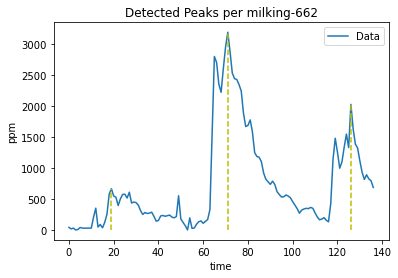

2
[100 203 267]
{1: 19, 2: 100}
{1: 126, 2: 267}


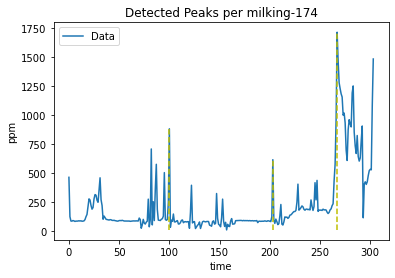

3
[ 30  79 115 161]
{1: 19, 2: 100, 3: 30}
{1: 126, 2: 267, 3: 161}


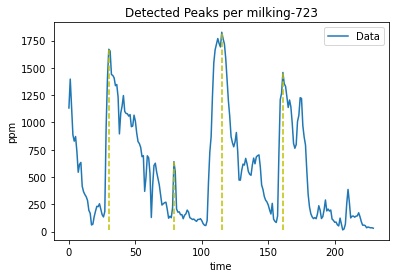

4
[ 52 123 171]
{1: 19, 2: 100, 3: 30, 4: 52}
{1: 126, 2: 267, 3: 161, 4: 171}


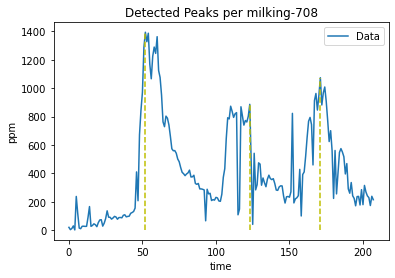

5
[ 60  96 137 196 255 314]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314}


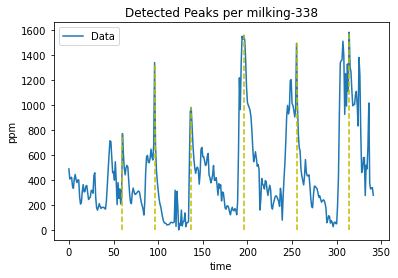

6
[  8  66 130 176 258 298]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298}


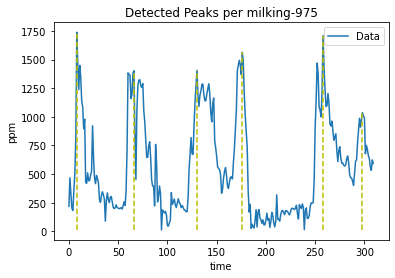

7
[ 11  85 126 236 303]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303}


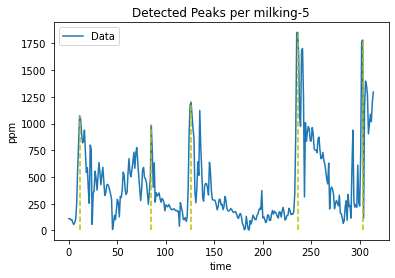

8
[ 40 127 180 235 274 309]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309}


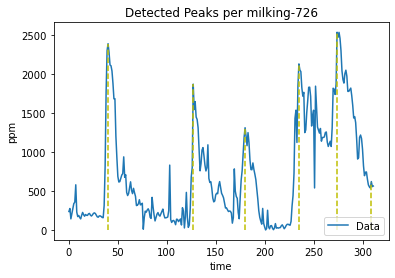

9
[ 15 118 178 263]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263}


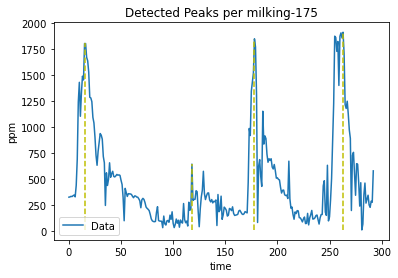

10
[  4  48 110 164 199 238]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238}


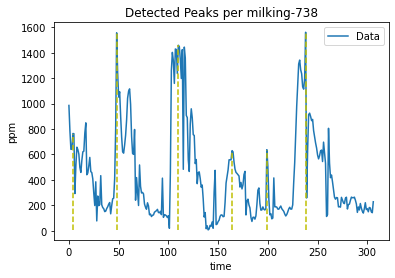

11
[ 25  72 109 169 207 263 305 358 398]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398}


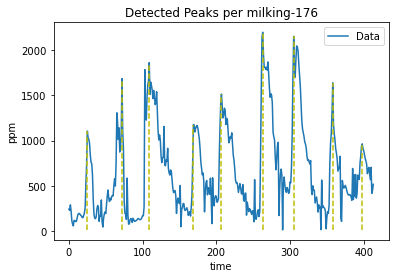

12
[  1  51 158 210 271 343]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343}


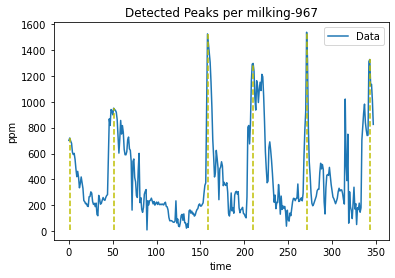

13
[ 34 118 189 259 325 376 438]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438}


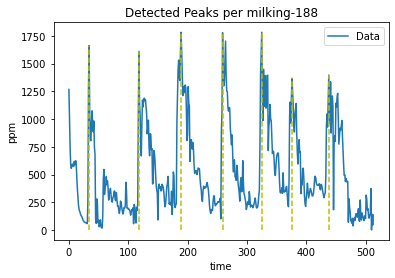

14
[ 36  72 134 183 243 282]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282}


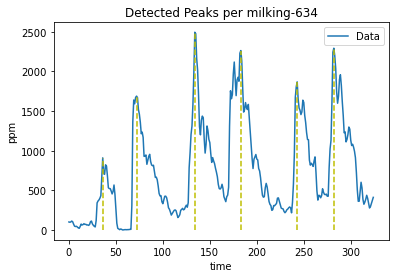

15
[ 30  70 115 154 203 287]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287}


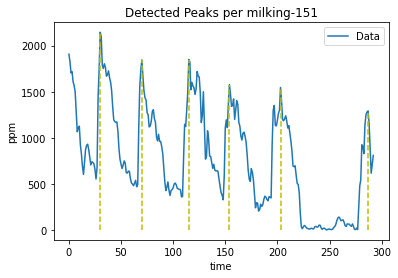

16
[  3  70 131 205]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205}


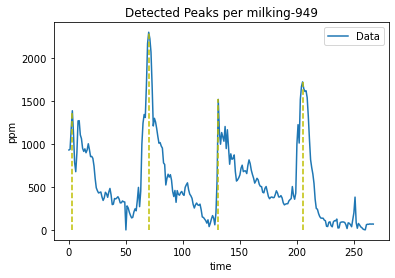

17
[  3  70 113 196 268 330 390]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390}


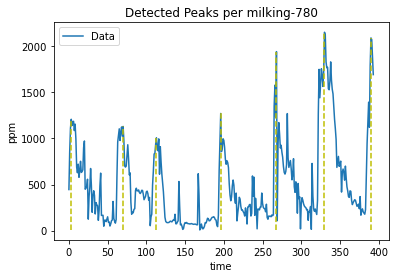

18
[  6  65 133 179 219 263 323]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323}


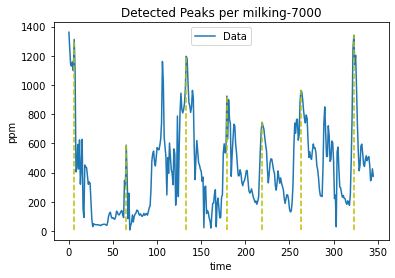

19
[ 12  84 124 186 242]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242}


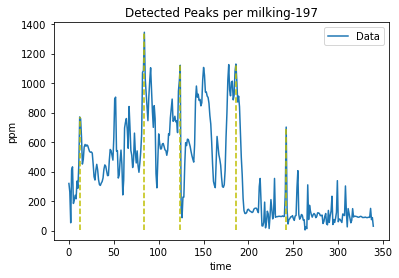

20
[ 20  83 206 271 347 387]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387}


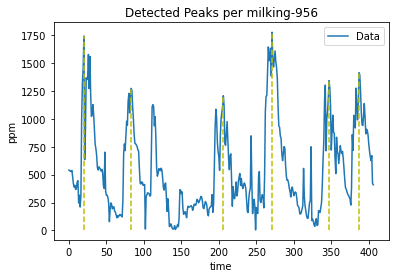

21
[ 24  64  99 136 195 324 379]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379}


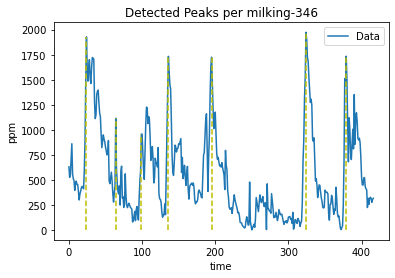

22
[ 28  86 131 185 259]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259}


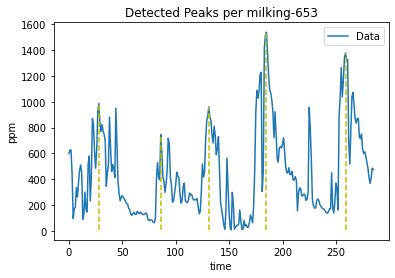

23
[ 37 105 165 227 291]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291}


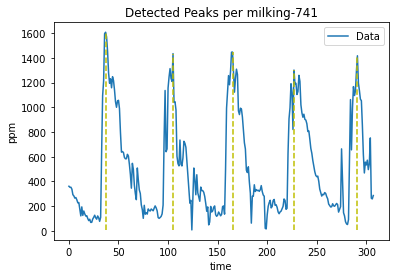

24
[ 65 106 143 201 237 274 317]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317}


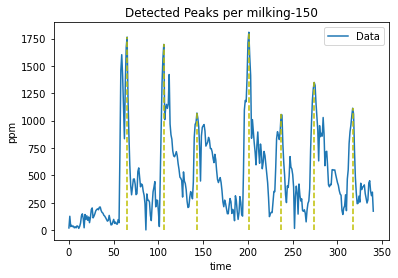

25
[ 13  52  94 149 186]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186}


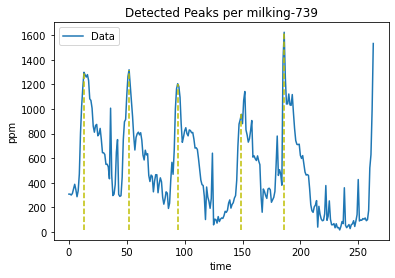

26
[  6  48 109 173 292 391 435 492]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492}


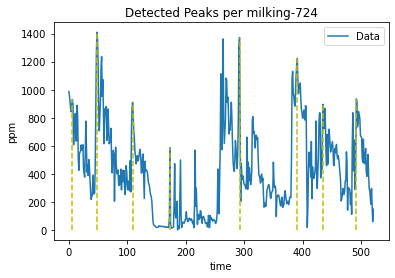

27
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN'}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN'}


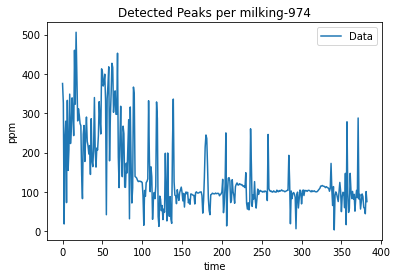

28
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN'}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN'}


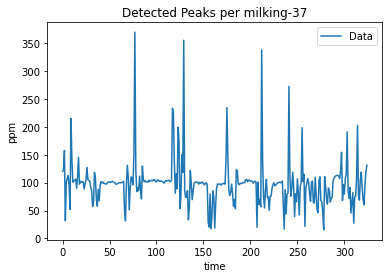

29
[ 77 195 253 308]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308}


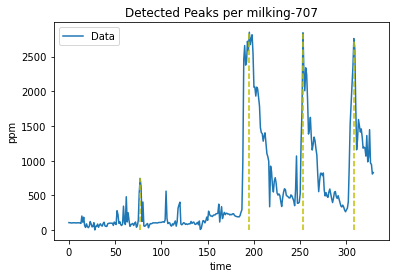

30
[  4  49 139 227 302 369 421]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421}


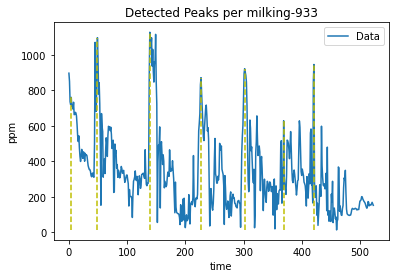

31
[ 10  80 149 196 248 299]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299}


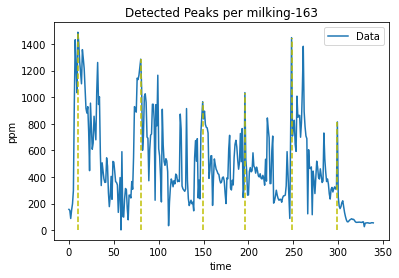

32
[128 243 323 361]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361}


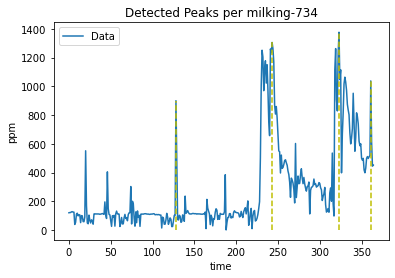

33
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN'}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN'}


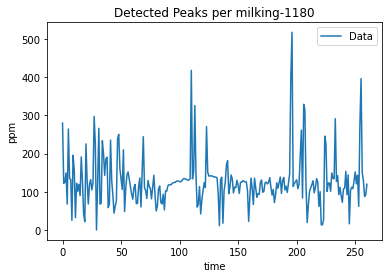

34
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN'}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN'}


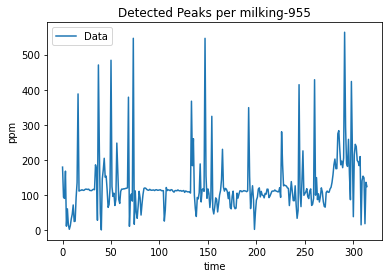

35
[ 32  81 155 192 227 263 371]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371}


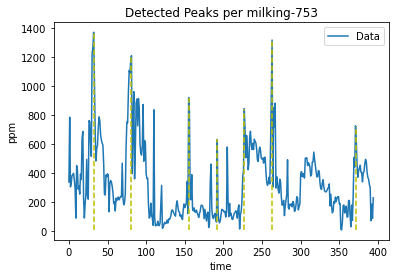

36
[  6  77 133 170 226]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226}


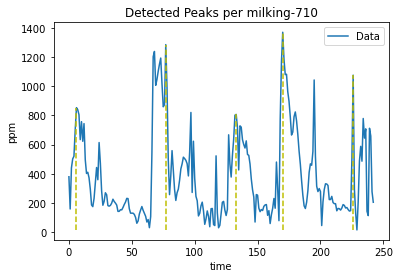

37
[ 16  84 151 229 286]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286}


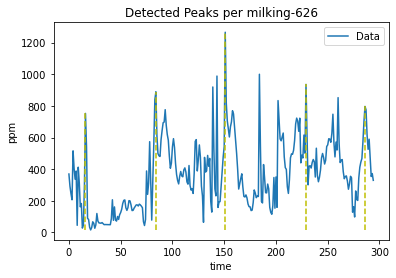

38
[ 26  77 131 190 256]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256}


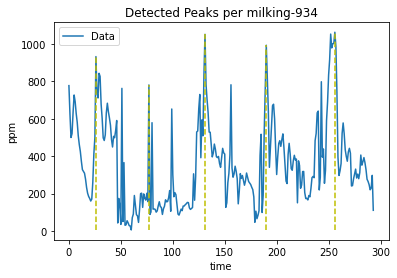

39
[ 21  83 146 212 268 339 376]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376}


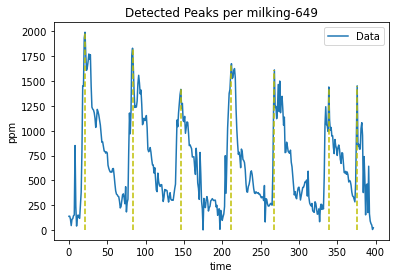

40
[ 83 196]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196}


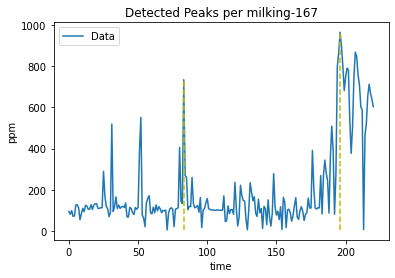

41
[114 153 220 292]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292}


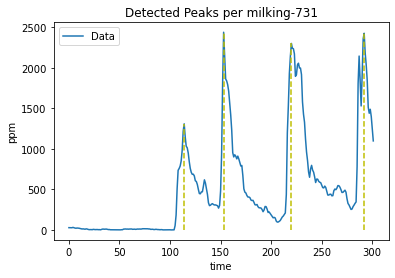

42
[166 226 306 363 431]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431}


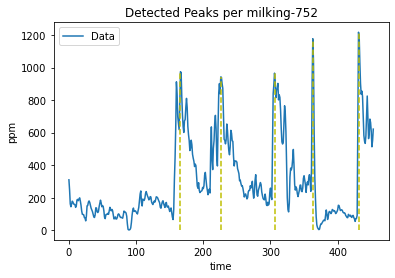

43
[ 29  98 222 295]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295}


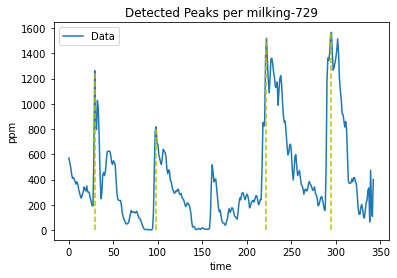

44
[ 16  63 214 277 347]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347}


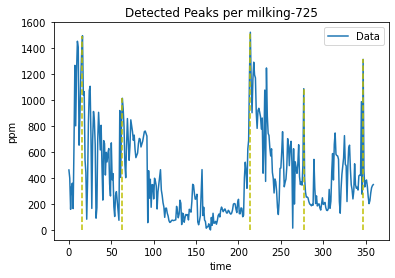

45
[  2  57 104 169 228 292 328]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328}


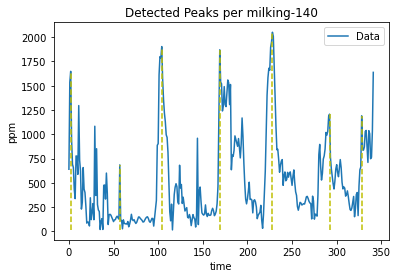

46
[ 11  87 213 275 335 400]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400}


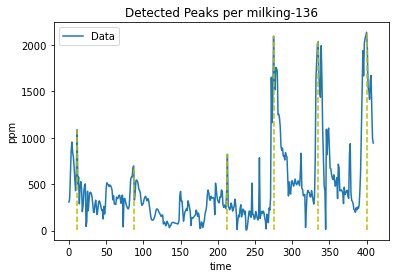

47
[ 13  88 159 210]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210}


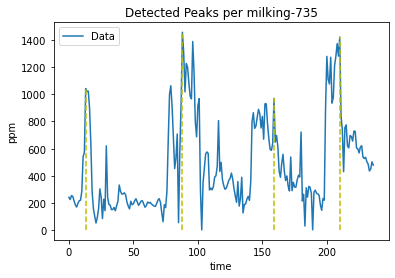

48
[ 71 139 193 229 282]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282}


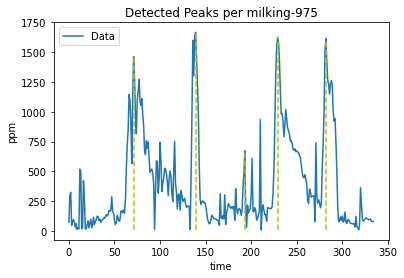

49
[ 59  98 146 204]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204}


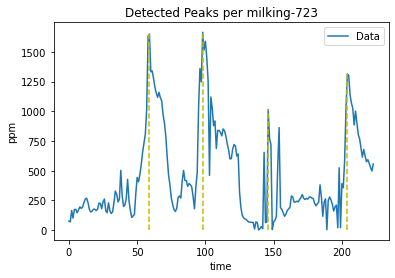

50
[ 19  83 192]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192}


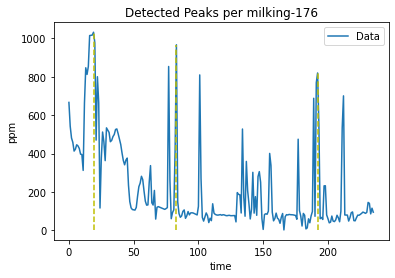

51
[ 42  92 134 173 212 254]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254}


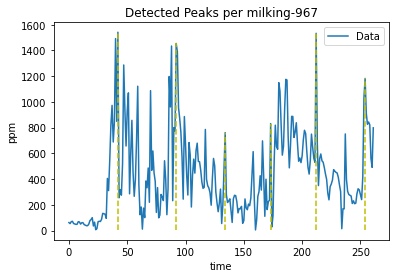

52
[  5 119 192]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192}


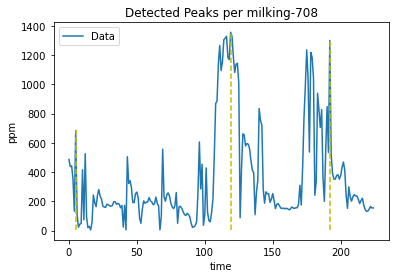

53
[  7  44 141 214]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192, 53: 214}


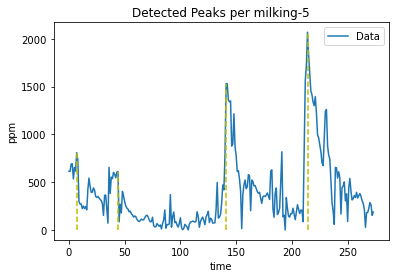

54
[ 11  92 161 198 235]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192, 53: 214, 54: 235}


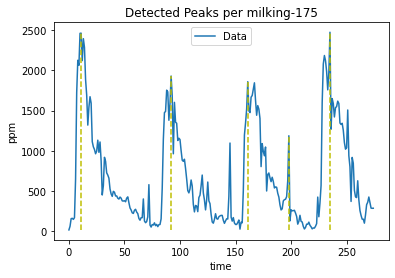

55
[ 26  88 139 212 289 340 399 440]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192, 53: 214, 54: 235, 55: 440}


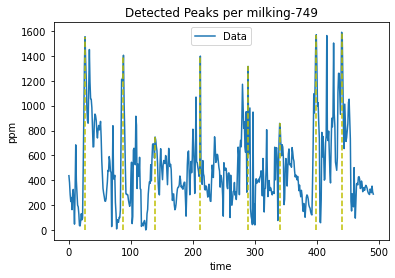

56
[  7 140 181 236 314]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192, 53: 214, 54: 235, 55: 440, 56: 314}


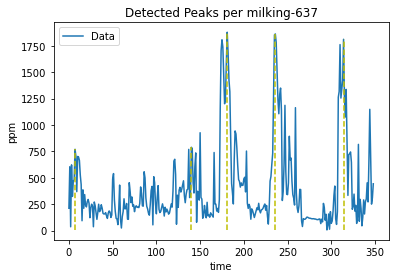

57
[ 26  90 155 223 263]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192, 53: 214, 54: 235, 55: 440, 56: 314, 57: 263}


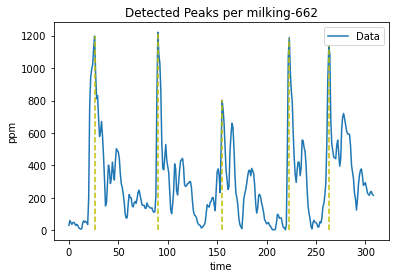

58
[ 32 111 167 215 281]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192, 53: 214, 54: 235, 55: 440, 56: 314, 57: 263, 58:

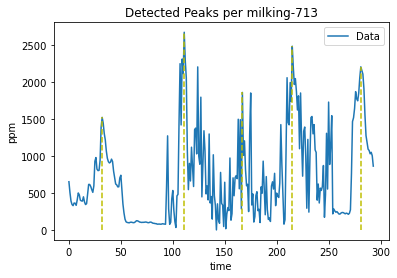

59
[ 62 120 181 225]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192, 53: 214, 54: 235, 55: 440, 56: 314, 57: 263,

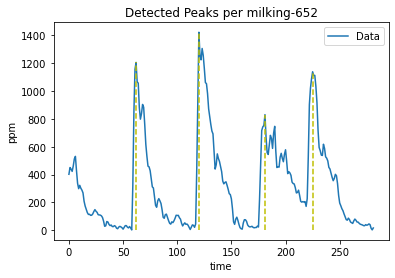

60
[ 27  73 151 196 271 324]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192, 53: 214, 54: 235, 55: 440, 5

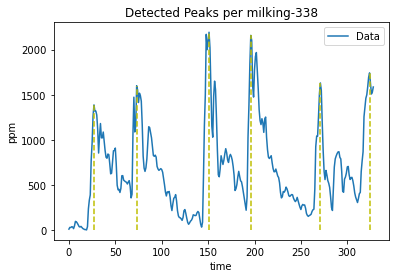

61
[ 33  92 160 216 280 344]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192, 53: 214, 54: 235, 55

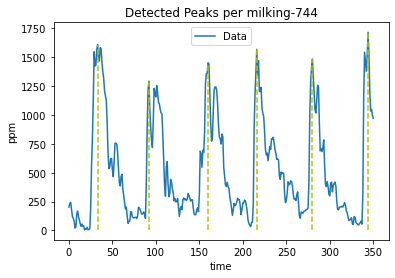

62
[  1  58 141 210 279]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192, 53: 214, 54: 235,

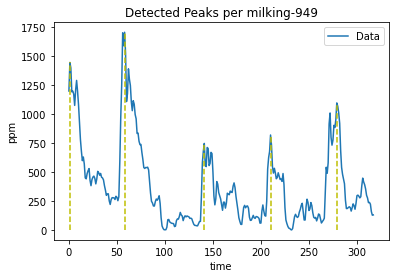

63
[ 14  73 152 228 301]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254, 52: 192, 53: 214, 

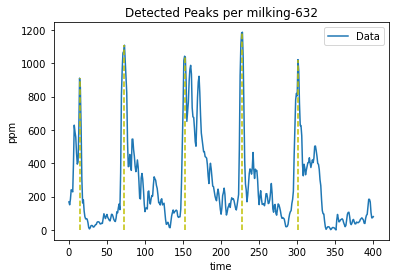

64
[  8  54  92 139 180 243 312 347]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 254,

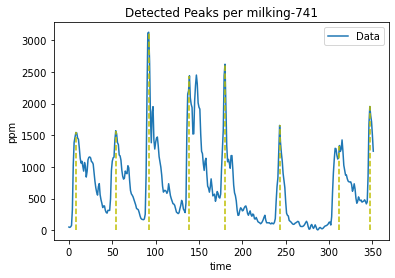

65
[ 50 120 187 262 324 377 427]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 192, 51: 

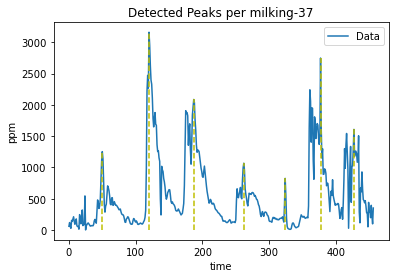

66
[ 16  79 127 194 253 311 356]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 1

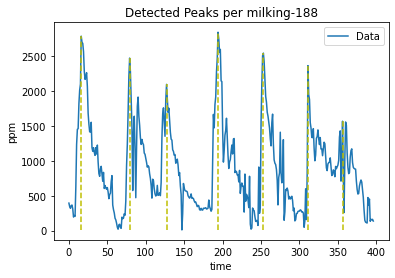

67
[ 47 107 147 207 246]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 204, 50: 1

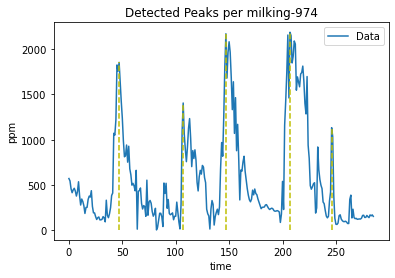

68
[ 20  74 143 212 252]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48: 282, 49: 20

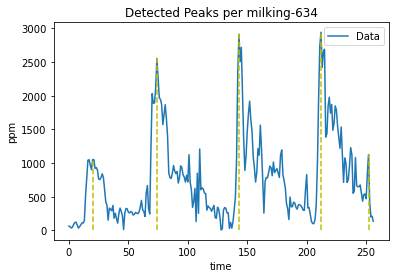

69
[ 10  57 176 219 258 310]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 210, 48:

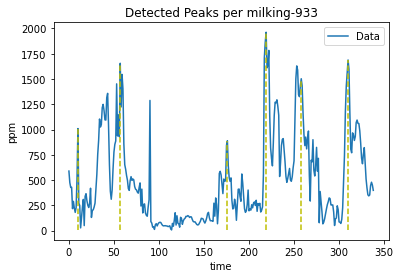

70
[ 24  77 151 210 273 334]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328, 46: 400, 47: 

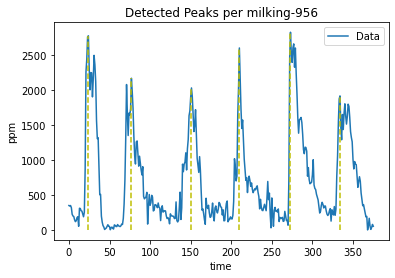

71
[  8  61  98 139 183 219 271 308]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328

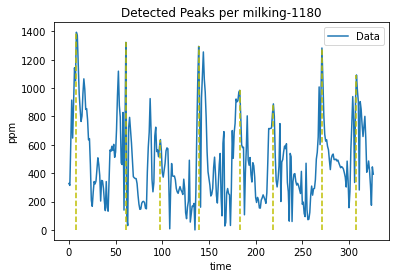

72
[  2  63 125 179 244 301]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328,

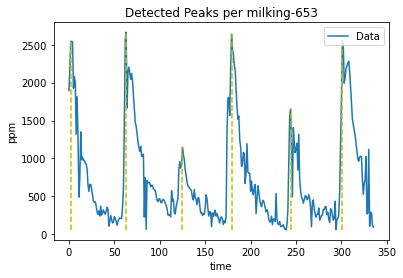

73
[109 177 214 282]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 44: 347, 45: 328

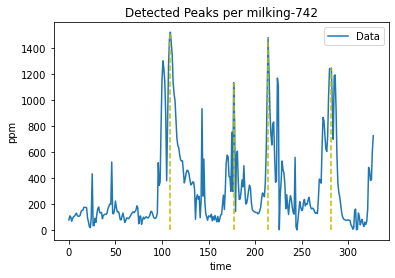

74
[ 36  76 140 177 238 294]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43: 295, 

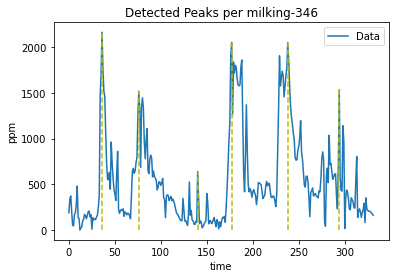

75
[  5  76 113 176 242 306]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431, 43

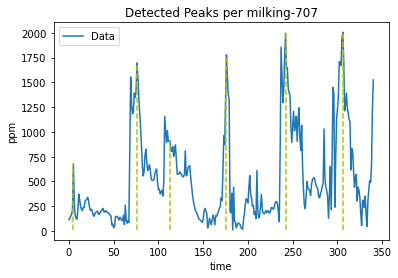

76
[  2  71 115 171 211]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 42: 431,

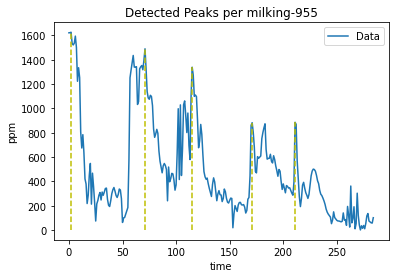

77
[  8  63 132 191 260]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292, 4

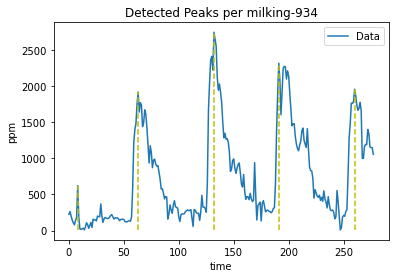

78
[  2  97 206 252]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196, 41: 292

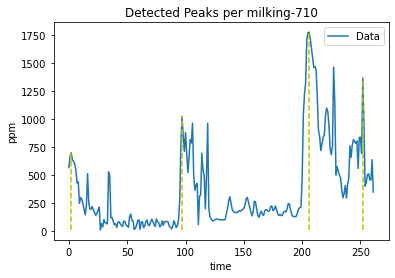

79
[ 41  88 130 168]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 40: 196,

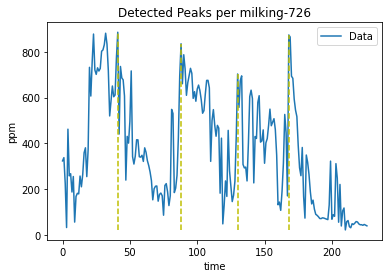

80
[ 34  83 142 214]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38: 256, 39: 376, 

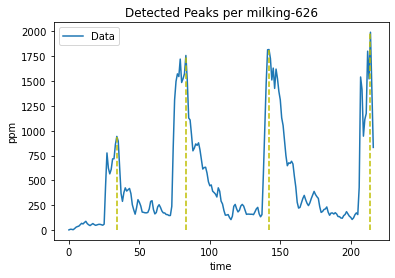

81
[ 69 128 199 259 304 360]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286, 38

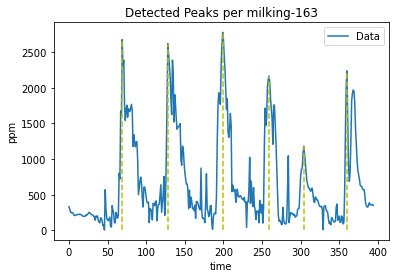

82
[ 27  92 158 208 244]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 37: 286

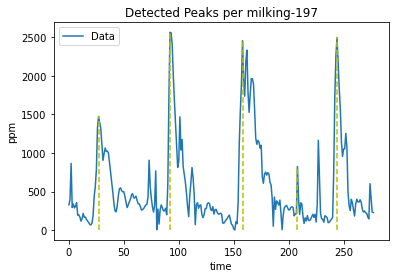

83
[  4  81 138 202 256]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371, 36: 226, 

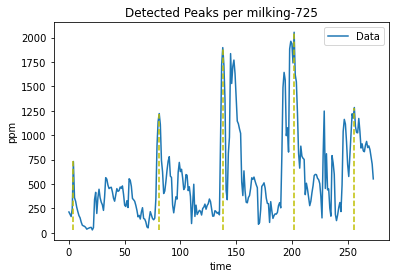

84
[  8  45 125 167 227 292]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'NaN', 35: 371

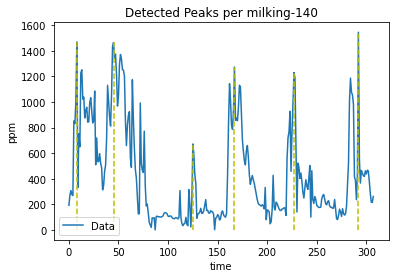

85
[  1  37  79 121 182 251 322]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN', 34: 'Na

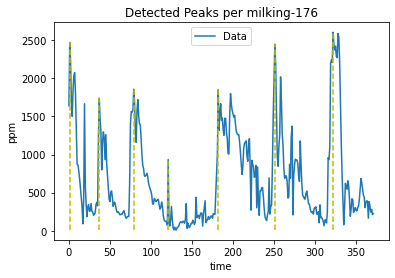

86
[ 11  53 104 166 235 295 361 425]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'N

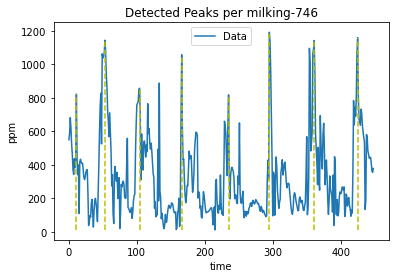

87
[ 50 106 168 241 305]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33: 'NaN',

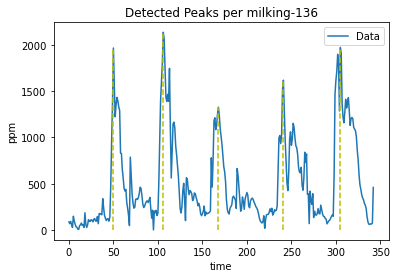

88
[ 46 110 179 236 325]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33

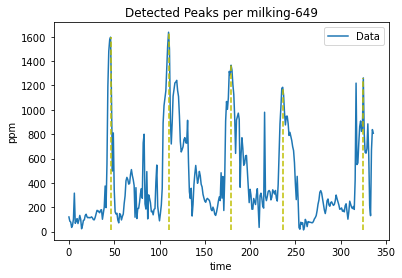

89
[  1  49 113]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 32: 361, 33:

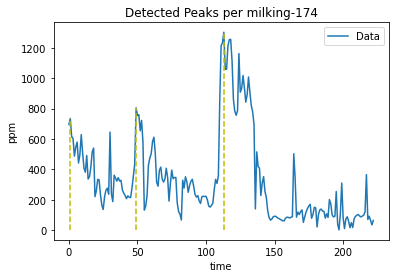

90
[ 13  81 155 212]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30: 421, 31: 299, 

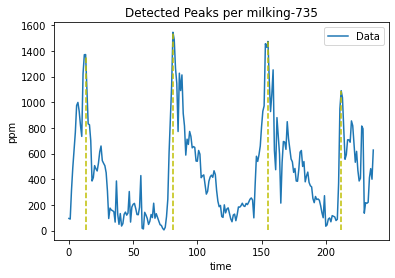

91
[ 16  88 128 179 231 293]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN', 29: 308, 30

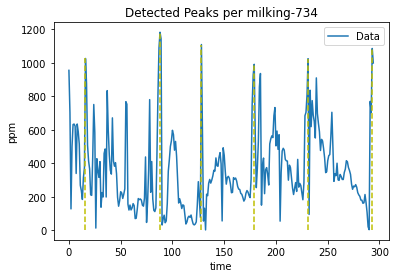

92
[ 45  82 136 189 259 304 351]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN',

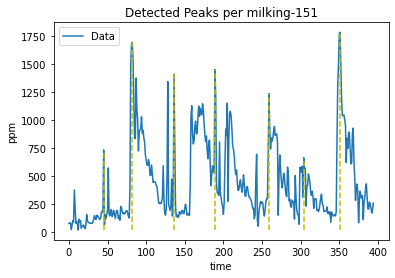

93
[  4  45  83 138 175 242 300 366]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN',

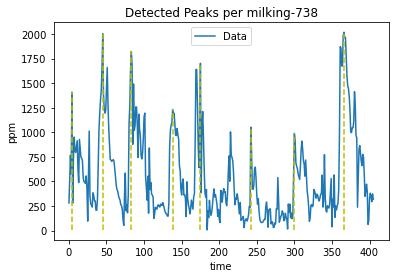

94
[ 38  95 160 218 292 329 377]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'N

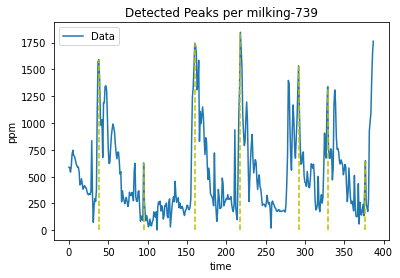

95
[285]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN', 28: 'NaN',

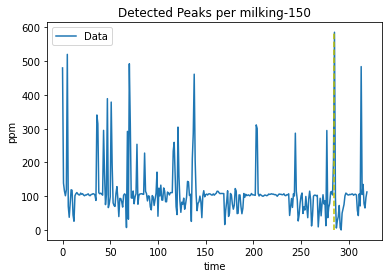

96
[108 169]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26: 492, 27: 'NaN

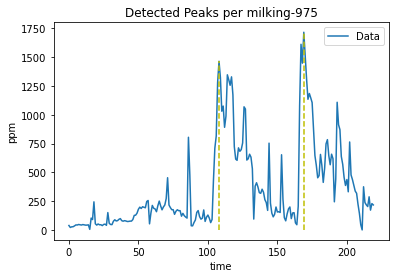

97
[  6  74 150 215]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186, 26

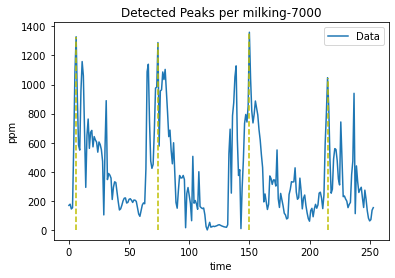

98
[ 40  76 181 240]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25:

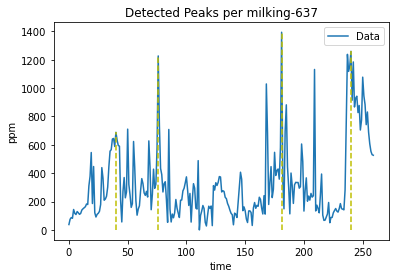

99
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN'}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 291, 24: 317, 25: 186

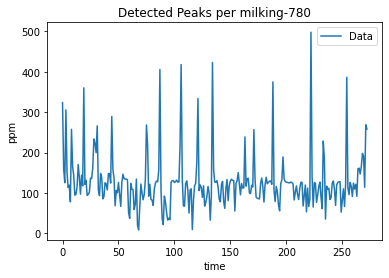

100
[ 51 101 228]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21: 379, 22: 259, 23: 

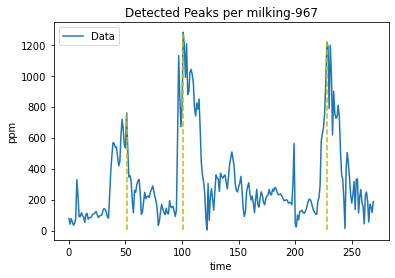

101
[  2  62 105 172 314 350 388 459 501 563]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 

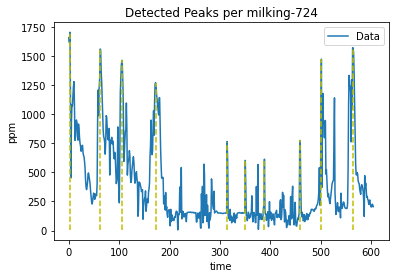

102
[ 16  77 119 182]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 2

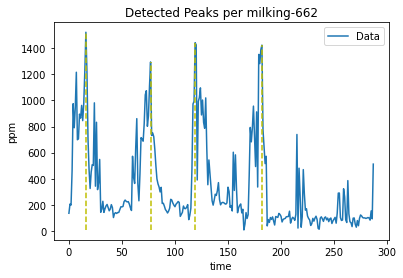

103
[141]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 242, 20: 387, 21:

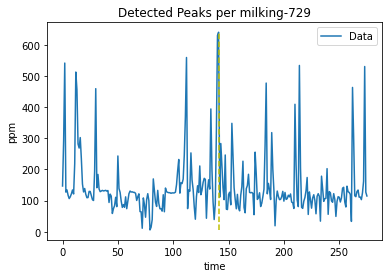

104
[ 58 134 195]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 18: 323, 19: 

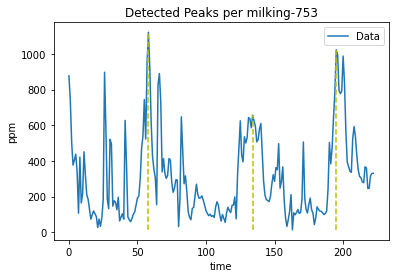

105
[ 38  73 158 206]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 16: 205, 17: 390, 

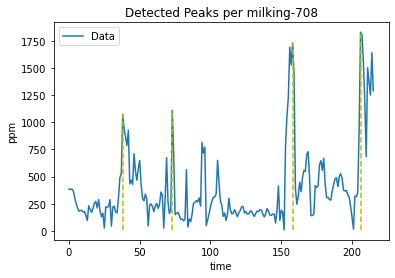

106
[ 31  97 147 196 249 298]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 287, 1

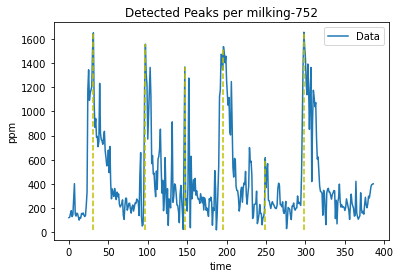

107
[ 30  65 116 178 259]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 282, 15: 2

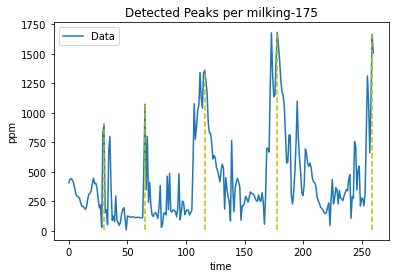

108
[  7 153 221 274 330]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 438, 14: 28

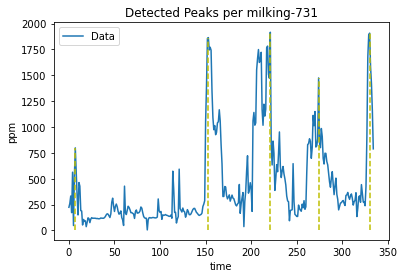

109
[  5  64 128 190 252 315 387 458]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 

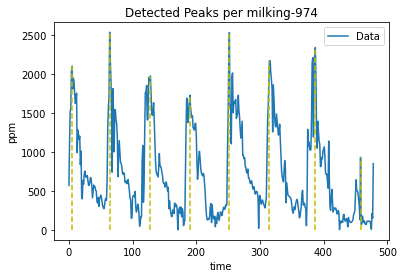

110
[ 63 118 180]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398, 12: 343, 13: 43

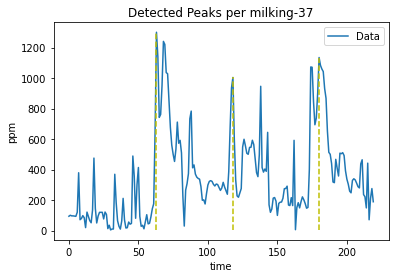

111
[ 29  69 121 178 223]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10: 238, 11: 398

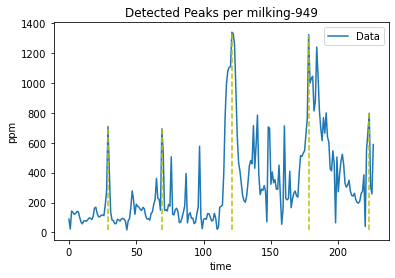

112
[ 44 107 179 243 315 368]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9: 263, 10:

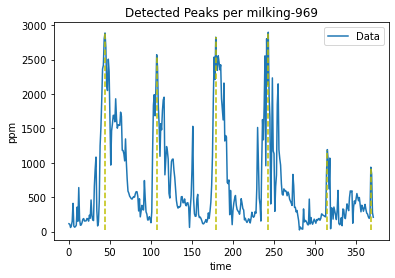

113
[ 12  86 154 212 293 340]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9:

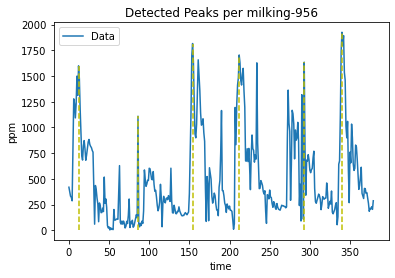

114
[ 10  89 130 200]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 6: 298, 7: 303, 8: 309, 9

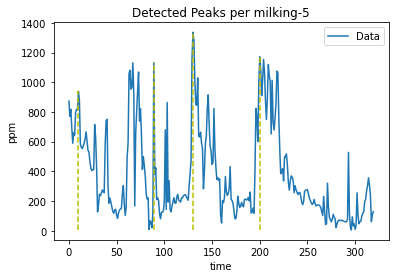

115
[ 23  81 140 198 280 320 393 450]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314, 

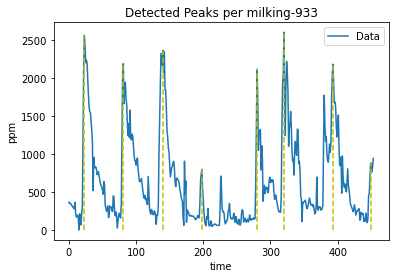

116
[ 37  91 137 186 226 265]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314,

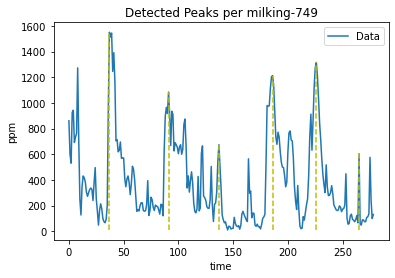

117
[  5  60  96 222]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5}
{1: 126, 2: 267, 3: 161, 4: 171, 5: 314,

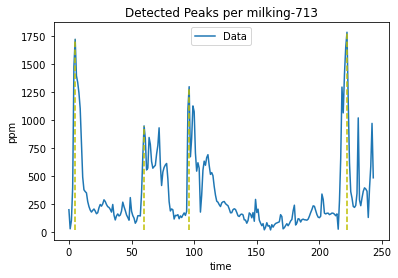

118
[  7  67 123 165 208 247]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7}
{1: 126, 2: 267, 3: 161,

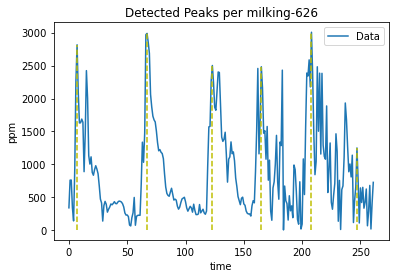

119
[ 16  81 134 171 232 303]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16}
{1: 126, 2: 267

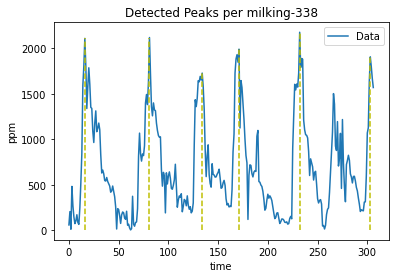

120
[ 24  60 118 225 283 349]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24}
{1: 12

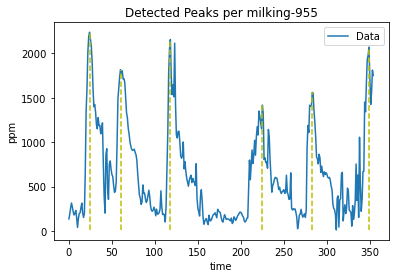

121
[ 24  61 128 171 223 273 338 381]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

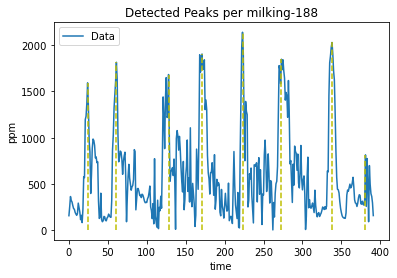

122
[ 56 106 170 236 312]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

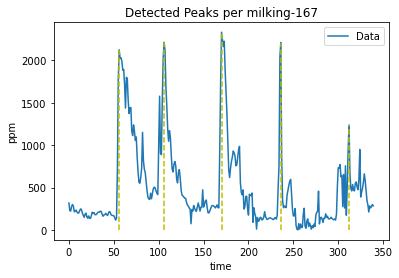

123
[ 59 130 189 232 287]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

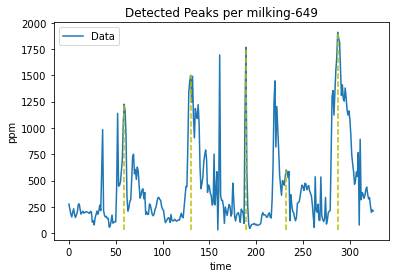

124
[  6  51 111 210 262]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

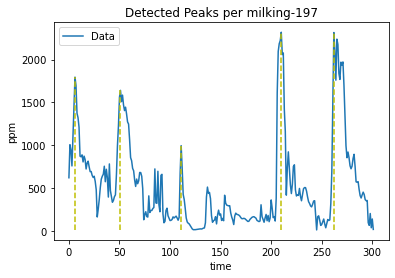

125
[ 20  71 111 153 196 249]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

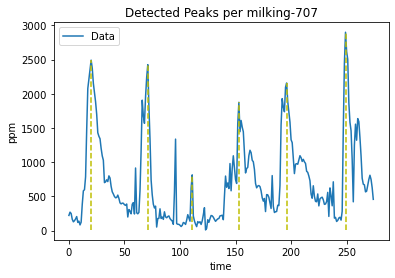

126
[ 28  86 125 168 226 272]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

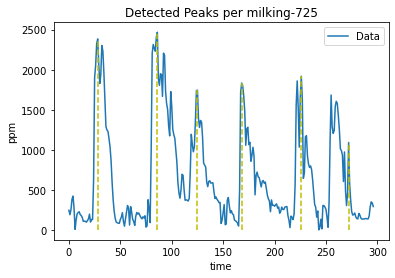

127
[ 10  68 109 154 193 237 275 311 348]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120

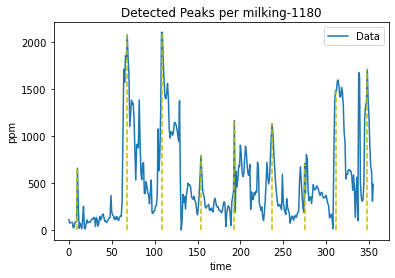

128
[  3  65 110 162 199 244 307 358 399 439 482 534]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 

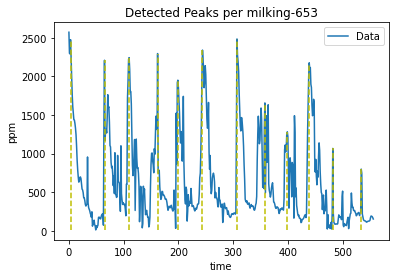

129
[ 30  92 179 222 269]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

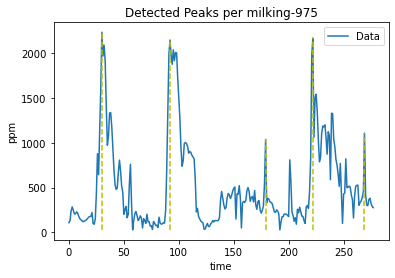

130
[ 10  78 261]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

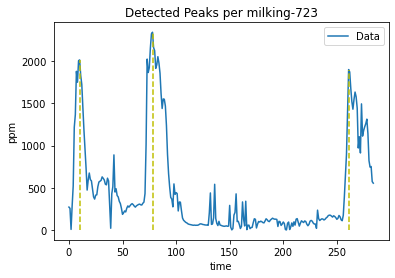

131
[  2  39 174 228]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

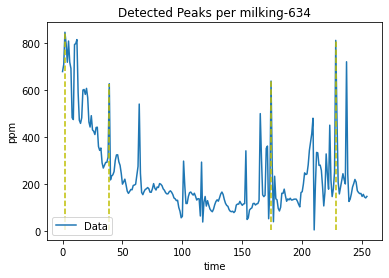

132
[ 20  70 125 183 251]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

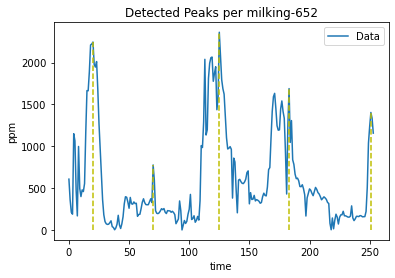

133
[  1  45 100 153 214 265 309 365 436]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120

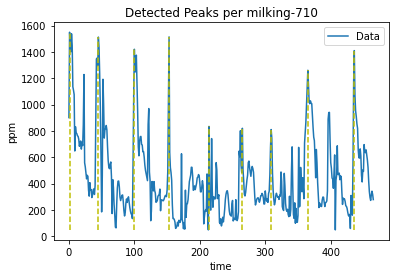

134
[ 12  69 122 184 251 301 357]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

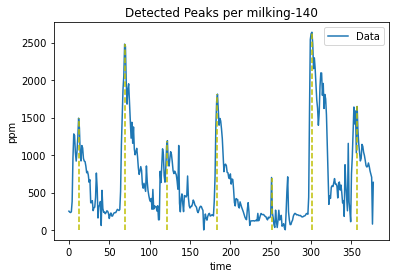

135
[ 34  84 141 194 248]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

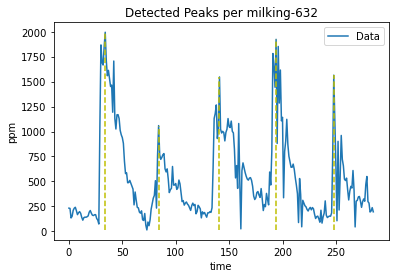

136
[ 27  73 182 248]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

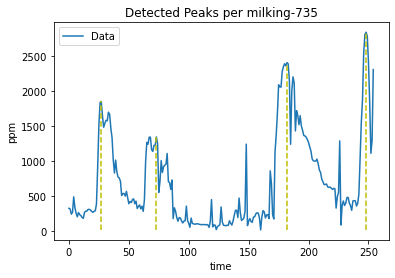

137
[ 13  60 110 250]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

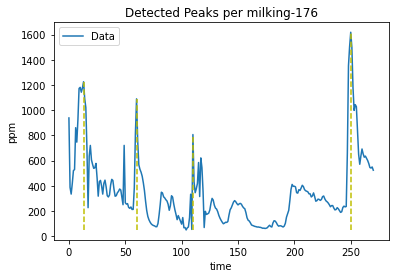

138
[ 31  96 160 233 284]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

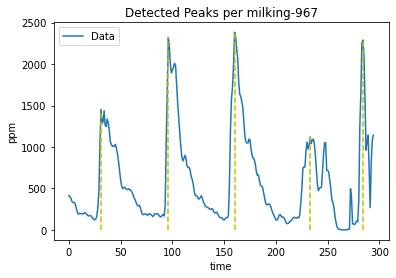

139
[  3  59 106 173 251]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

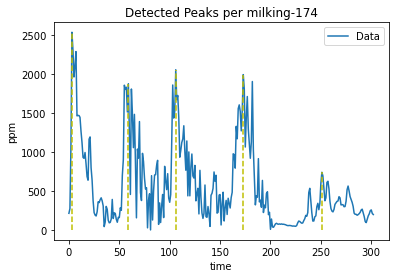

140
[  7  44 104 182 228 268 303]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

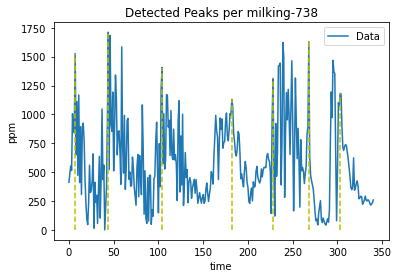

141
[158 218]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123:

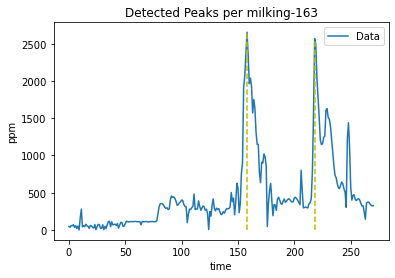

142
[ 11  76 115 165]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

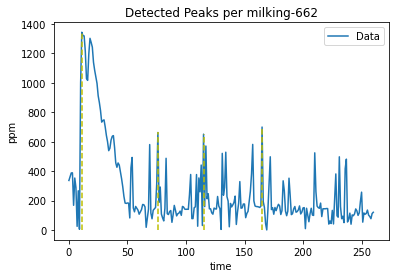

143
[107 226]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123:

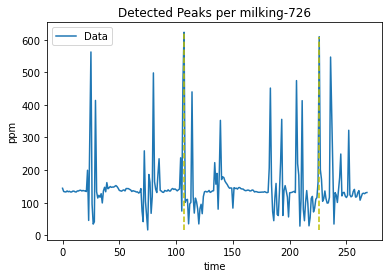

144
[169 211 255 315]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

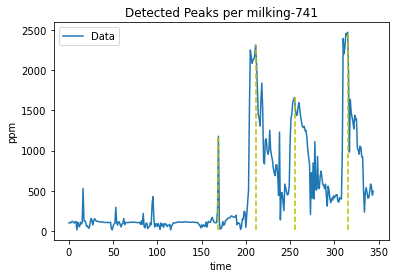

145
[ 30  68 133 177 236 297 340 386 475]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120

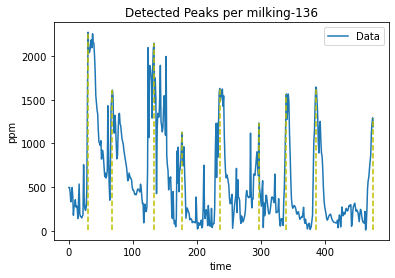

146
[ 24 102 168 249]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

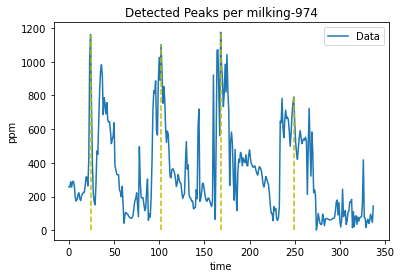

147
[ 43  82 138 196 248]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

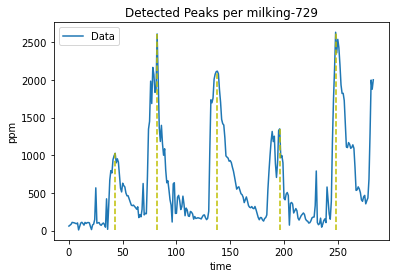

148
[  2  38  98 134 170 211 261]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

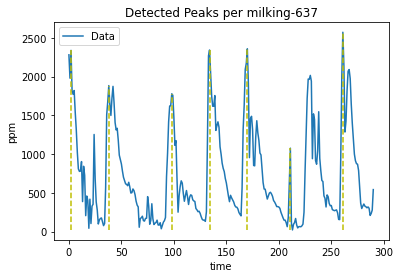

149
[  2  49 110 182 219]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

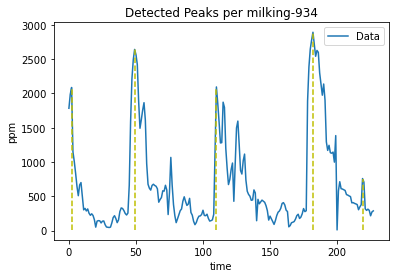

150
[  2 124 180]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

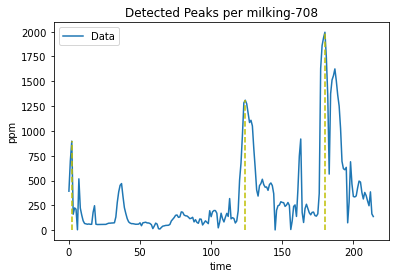

151
[ 38 109 150 207]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

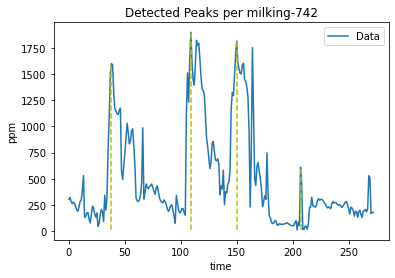

152
[ 30  78 115 150 198 237 392]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

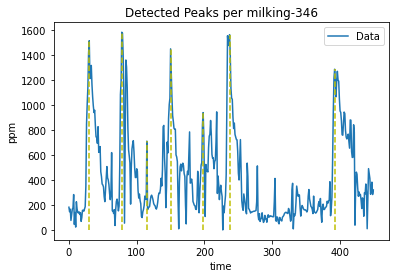

153
[  6  83 132 299 352]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

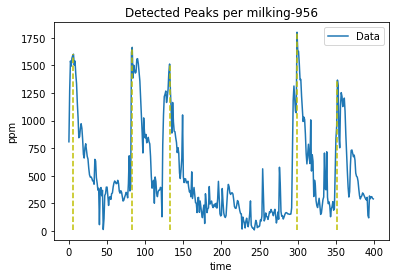

154
[126 187 262 319]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

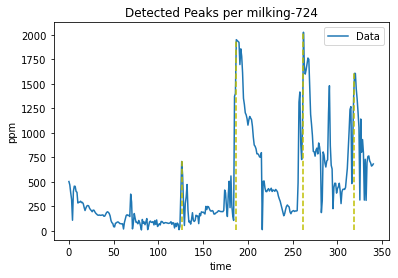

155
[ 31  82 139 174 214 270 334]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

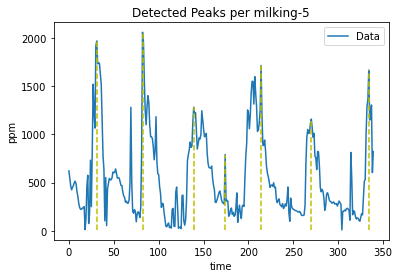

156
[  1  47  87 153 200 255]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

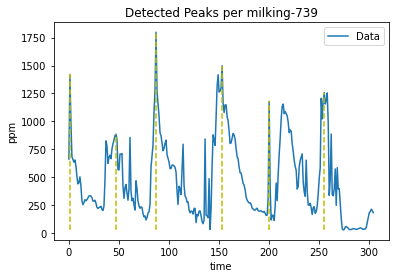

157
[ 51 116 170 210 270]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

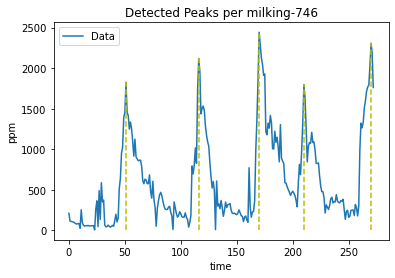

158
[  5  65 136 205 261]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

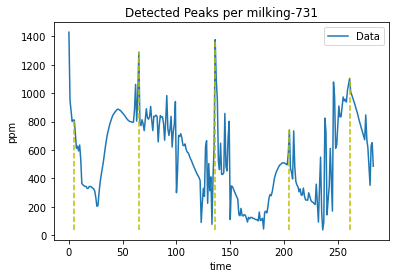

159
[ 42  93 166 232 282]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

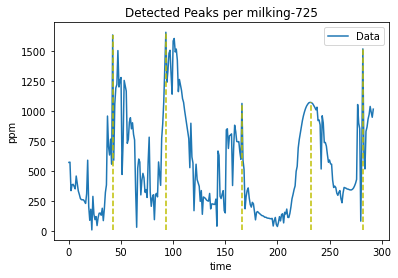

160
[ 11 118 166 203 254]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

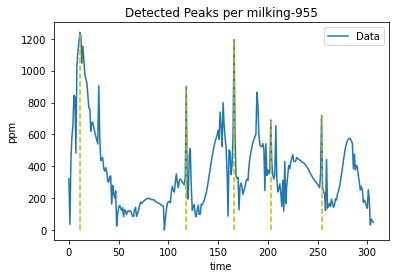

161
[  8  69 153 224 355 441]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

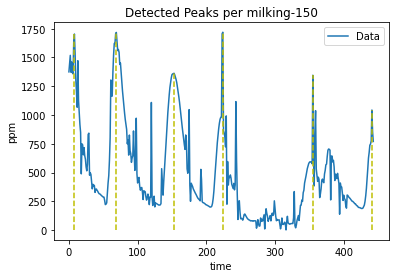

162
[ 30  71 111 155 222 257 319]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

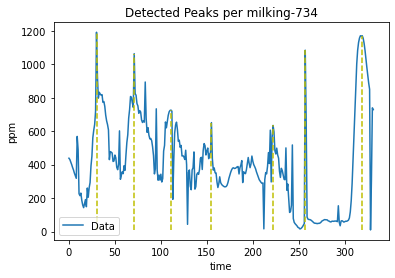

163
[ 30  96 199 265 330]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

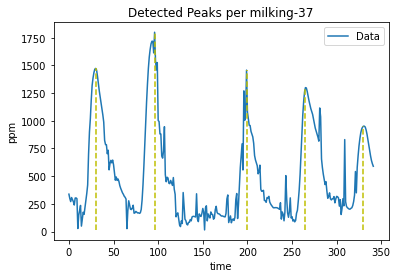

164
[  8  47 109 177 234 318]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

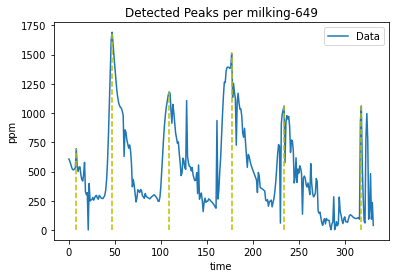

165
[ 16  73 135 189 251 294]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

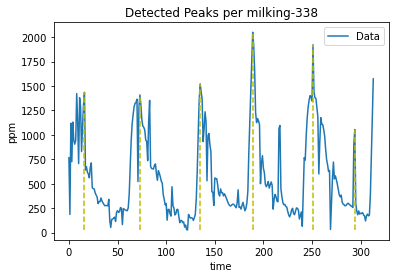

166
[ 15  56 152 250 328]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

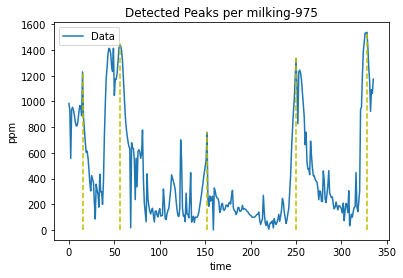

167
[  9 122 177 244]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

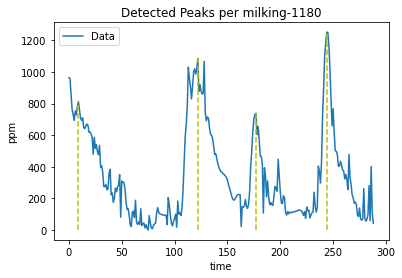

168
[ 16 129 164 205 258]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

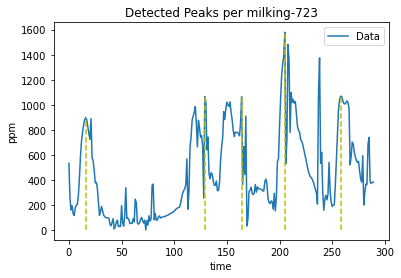

169
[ 67 141 183]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

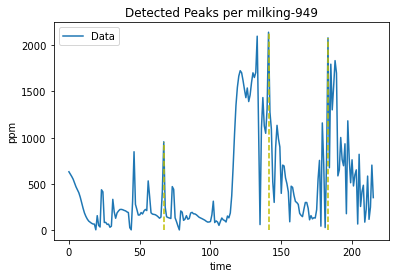

170
[ 39 113 159 213]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

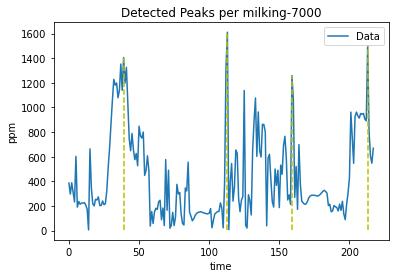

171
[ 33 104 165 215 254 317 376]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

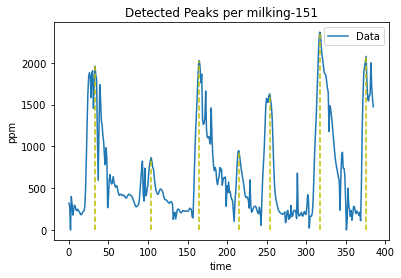

172
[ 30  84 132 201 250 308]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

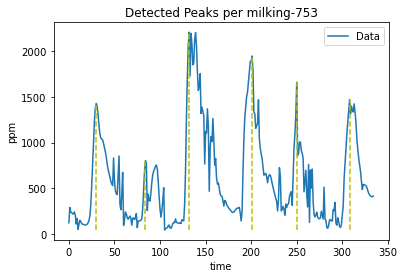

173
[ 28 120 194 257 316]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

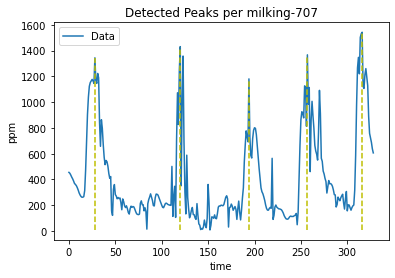

174
[  1  51 107 163 201 257 294 348 385 443 480]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119:

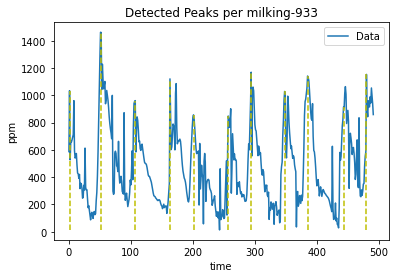

175
[ 71 148 205 254]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

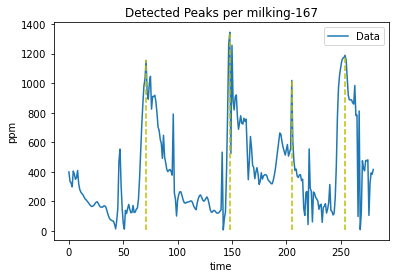

176
[ 12  56  97 154 200 249]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

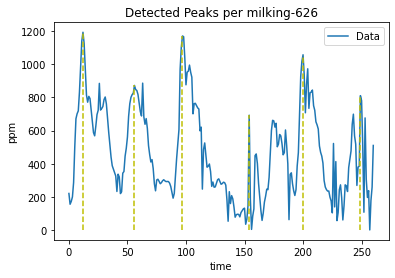

177
[ 50 185 256]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

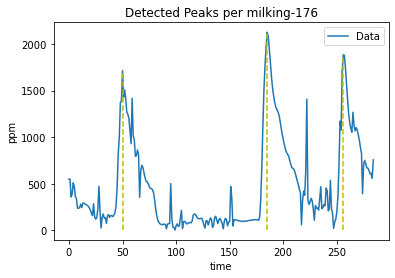

178
[ 25  85 126 216]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

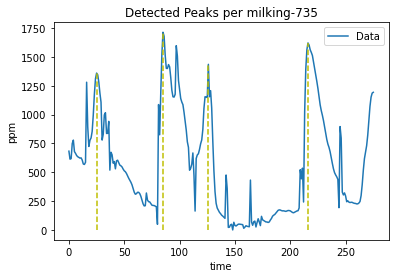

179
[  4  55 114 177 232]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

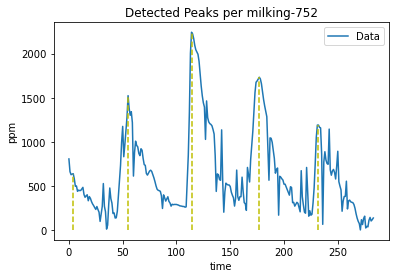

180
[ 40  80 131 167 205 245 282]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

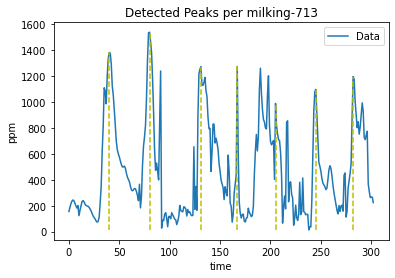

181
[ 13  95 160 203 262 307]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

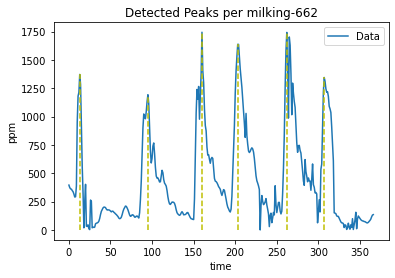

182
[ 91 132 198 267 315]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

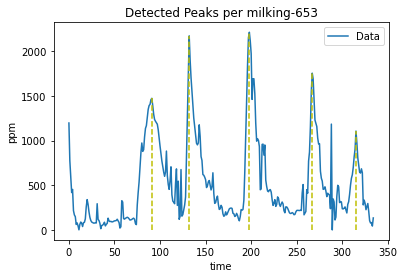

183
[133 168 235]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

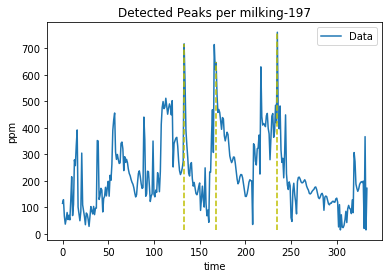

184
[ 11  84 133 211 286]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

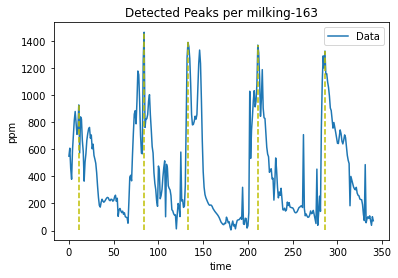

185
[ 88 177 224 260 308]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

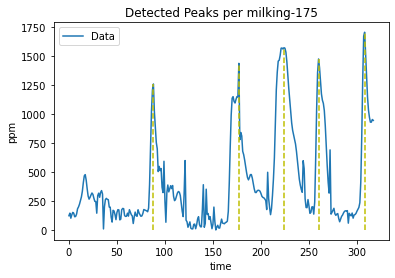

186
[ 14  57 141]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

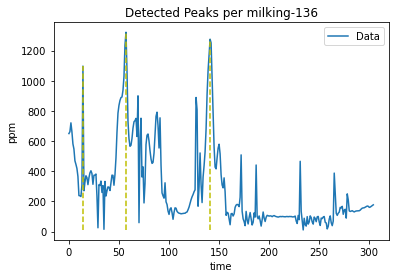

187
[ 24  60 130 187 263]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

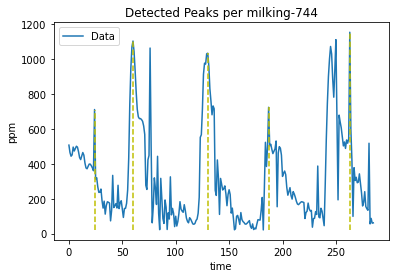

188
[ 26  89 223]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

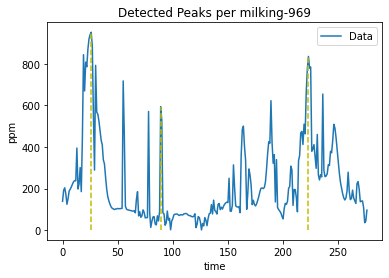

189
[ 13  63 229]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

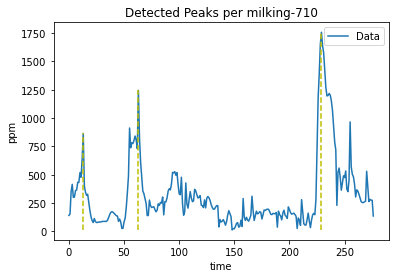

190
[  5  68 131]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

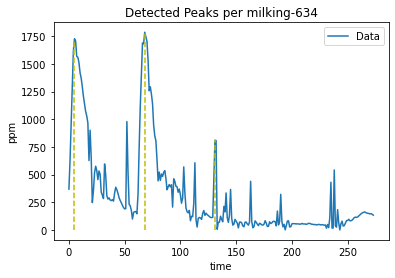

191
[ 28  86 135 285]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

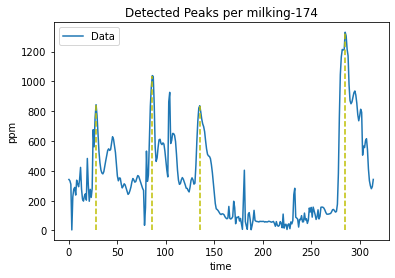

192
[ 48  94 190 263]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

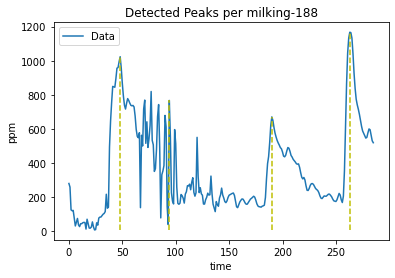

193
[ 90 139 206]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

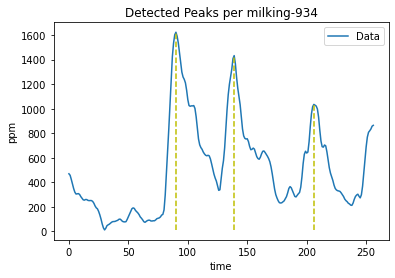

194
[ 46  92 141 232]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

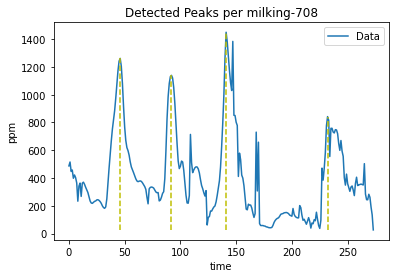

195
[ 27  80 123 202 266 320 401]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

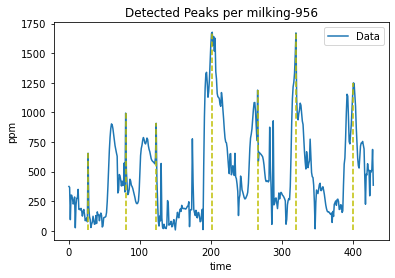

196
[ 20  58 114 172 216 296 345 419 455]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120

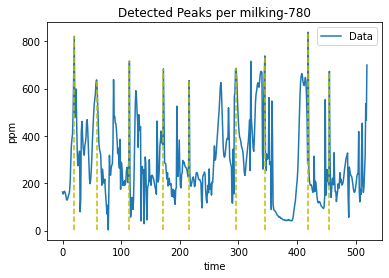

197
[ 34 112 161 220]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

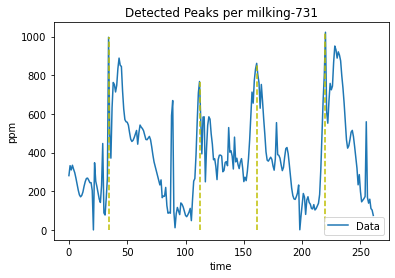

198
[ 38  78 117 153 209]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

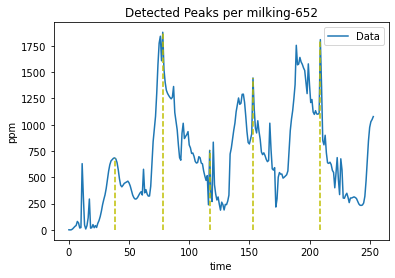

199
[ 19 120 190 249]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

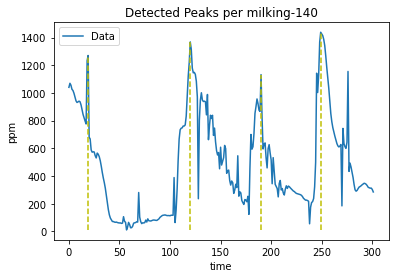

200
[  7  92 164 223]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

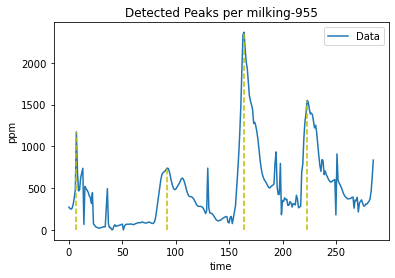

201
[ 16 230]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123:

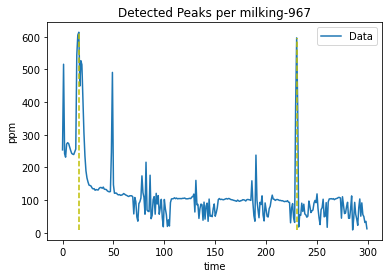

202
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123: 59, 12

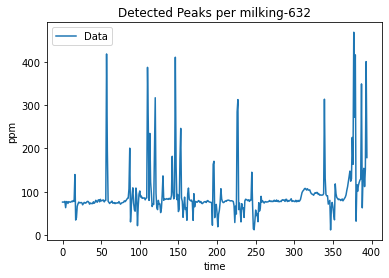

203
[ 45 128 192 246 308]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

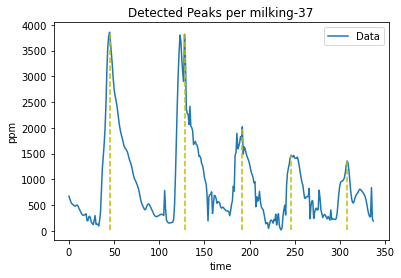

204
[  6 160 222 280 320 363]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

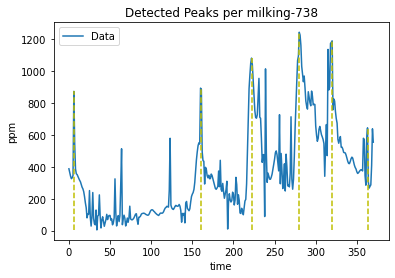

205
[  2  52 176 230 266 333]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

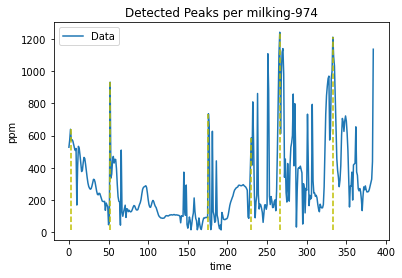

206
[  4  62 168 249 291 327]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

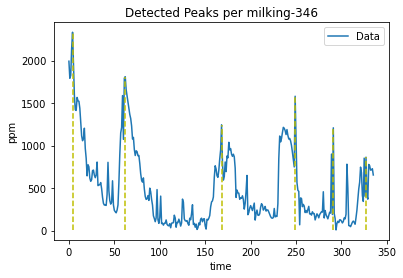

207
[  3  56 225 263]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

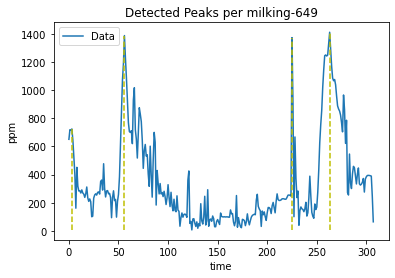

208
[  9  44  87 129 186 231]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

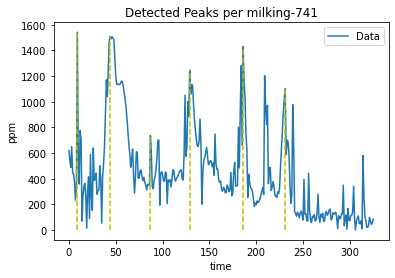

209
[  7  68 138 196 269 323]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

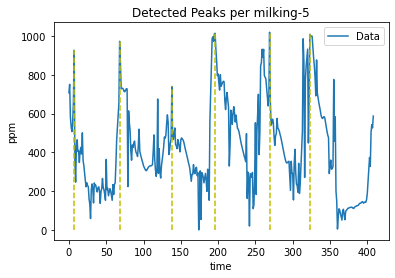

210
[  5  80 142 202 266 317]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

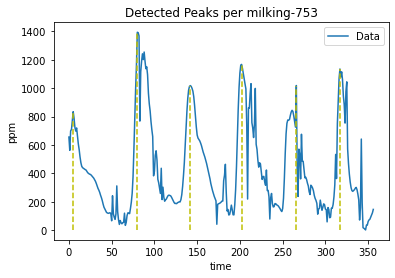

211
[122 227 267 344 381]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

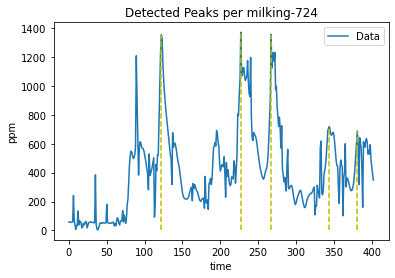

212
[ 18  60 250]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

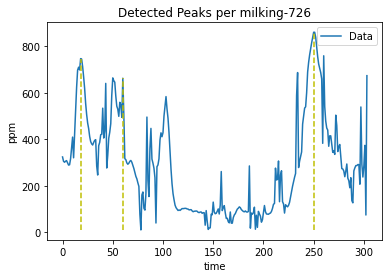

213
[  9  50 108 145 184 315]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

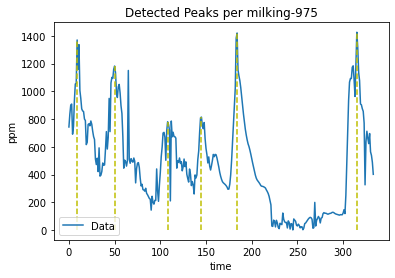

214
[ 22  74 111 163 279 376]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

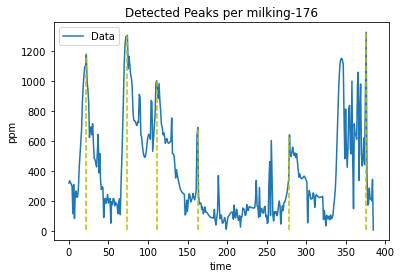

215
[ 14  79 159 219 256]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

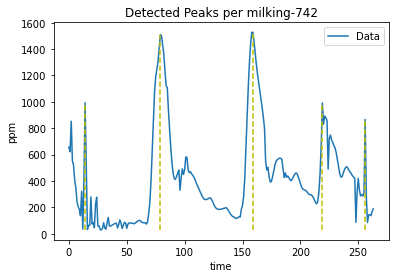

216
[  5  41  96 135 224 265 303]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

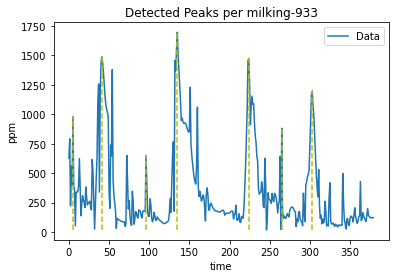

217
[ 19  81 155 218 358]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

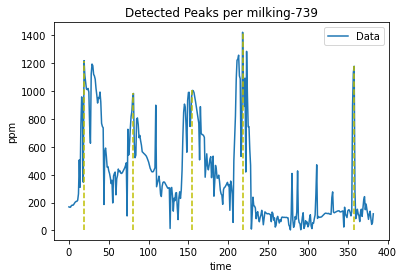

218
[  7  81 180 246 314 408]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

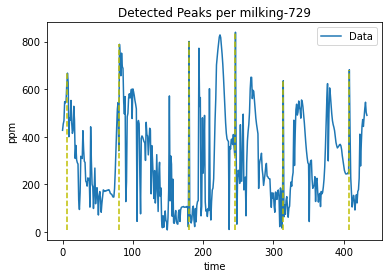

219
[ 36  94 155 216 346]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

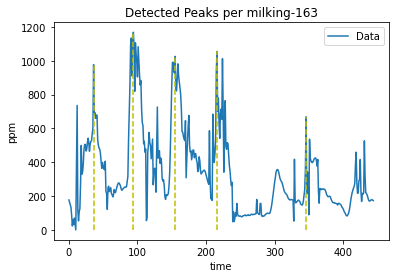

220
[  6 116 179 215 270]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

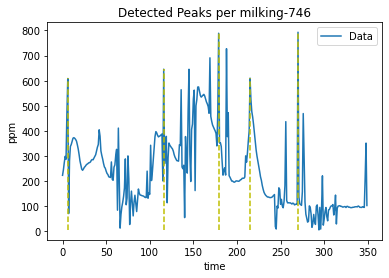

221
[122 184 240 278 335]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

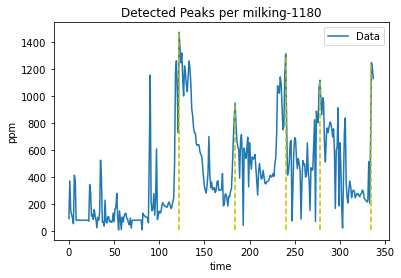

222
[  2  42  83 146 185 253]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

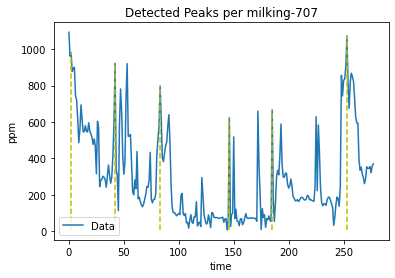

223
[ 41  91 145 188 259]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

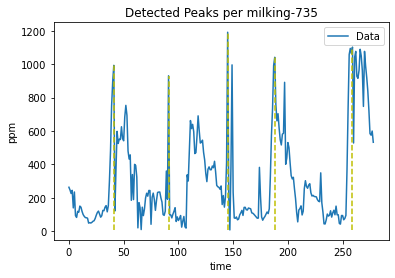

224
[ 43 114 153 203 260]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

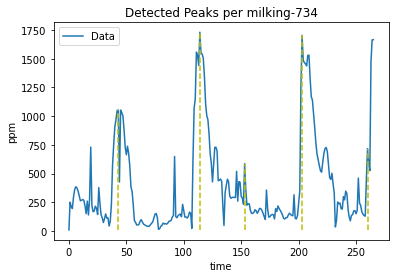

225
[  1  58 104 162 200 236]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

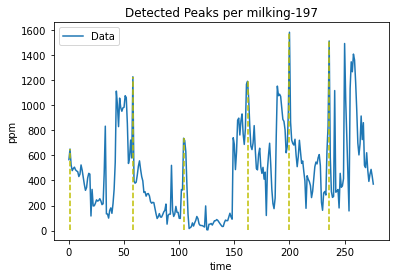

226
[ 38  93 158 204]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

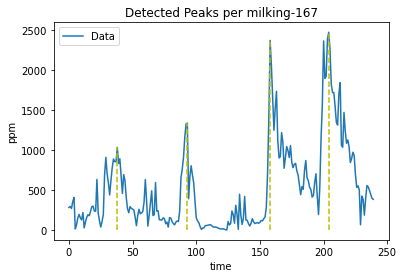

227
[  6  74 191 249]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

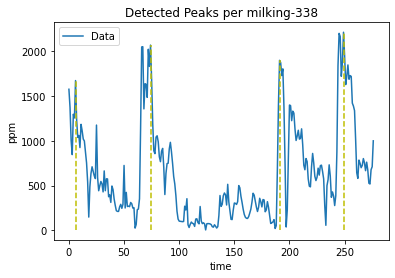

228
[  9 101 182 240 285 355 400]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

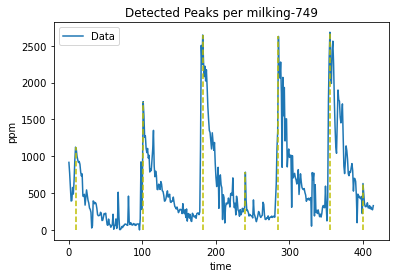

229
[ 26  85 146 187 229 282 325]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

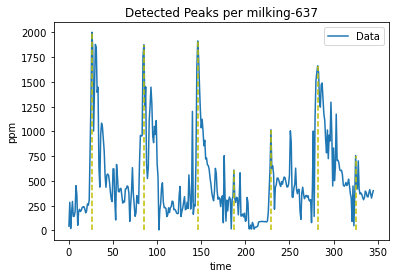

230
[  4  48 130 174 244 295 347]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

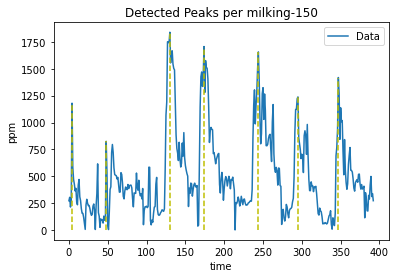

231
[ 22  77 133 205]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

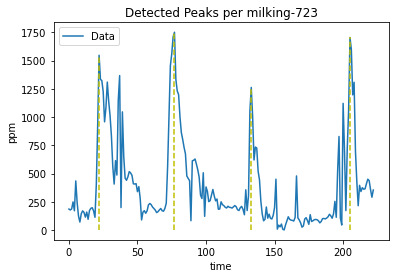

232
[ 33  98 154 215 253]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

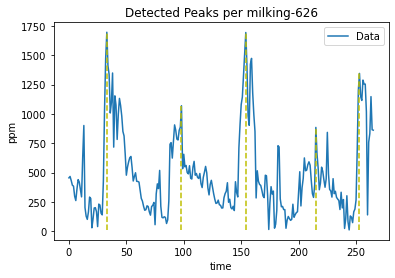

233
[ 28  76 123 159 229]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

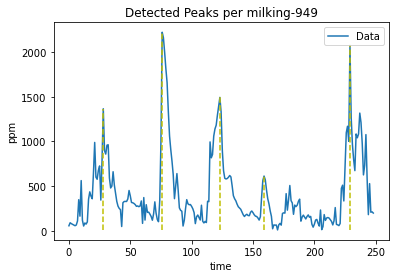

234
[ 34  71 132 191 247 318]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

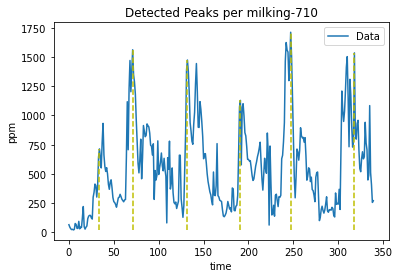

235
[ 42 101 172 247 303]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

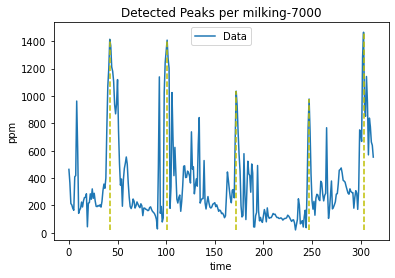

236
[ 31  66 110 148 183 220 283 322]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

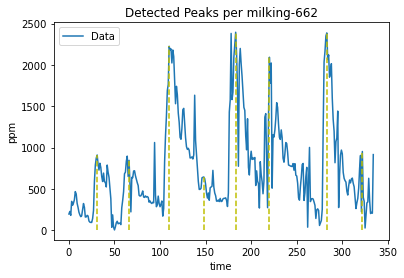

237
[  3  43 101 144 185 248 287]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

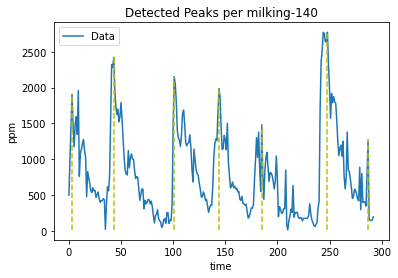

238
[  2  69 137 207]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

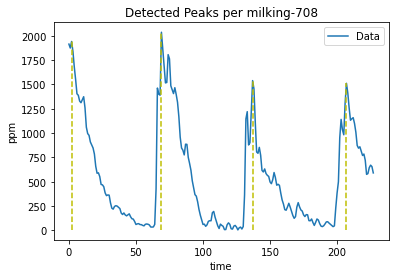

239
[  7  47  88 146 209 248 311]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

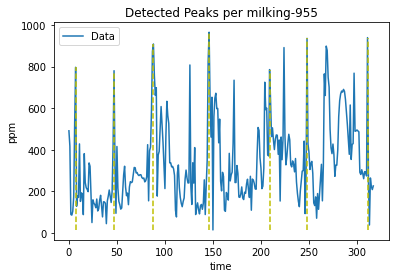

240
[  6  44  85 149 227 296 339]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

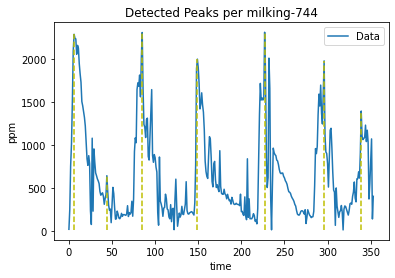

241
[ 52 126 218 287 344]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

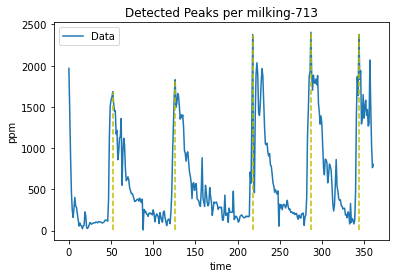

242
[  4  91 154 212 278 330 386 427]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

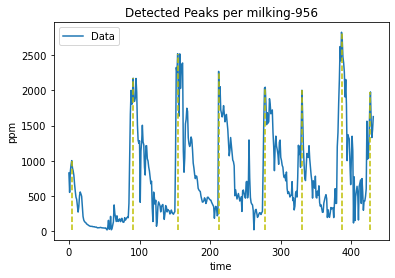

243
[ 18  73 142 212 305]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

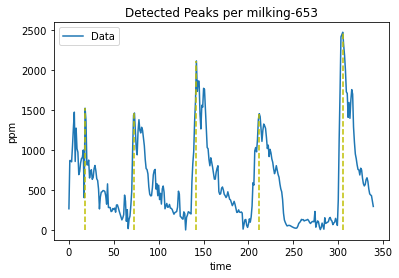

244
[ 36 105 166 209]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

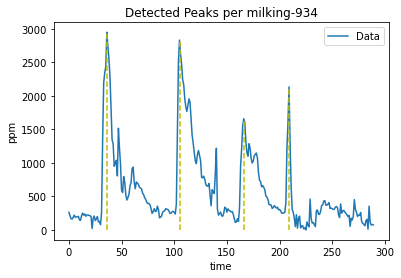

245
[ 40 111 159 242 298 343 395]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

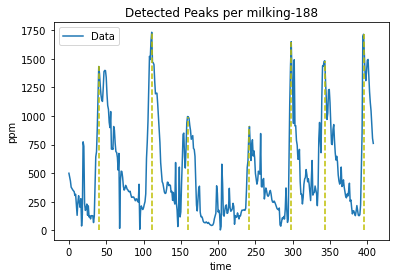

246
[108 185 252]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

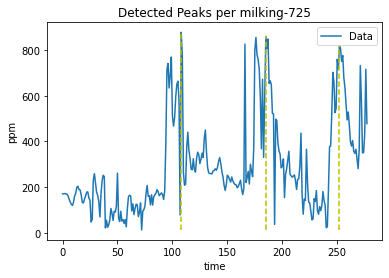

247
[ 56  95 162 198]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

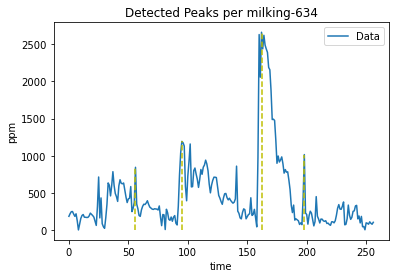

248
[ 23  78 139 365 418]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

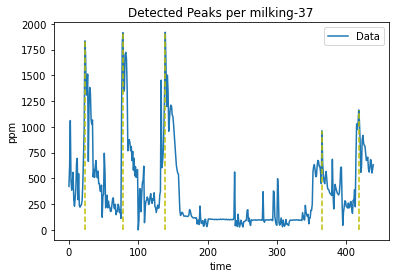

249
[ 48 104 150 224 269 333 385 456]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

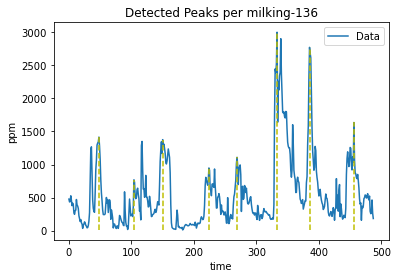

250
[ 35  85 126 163 217 272 330 392 437]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120

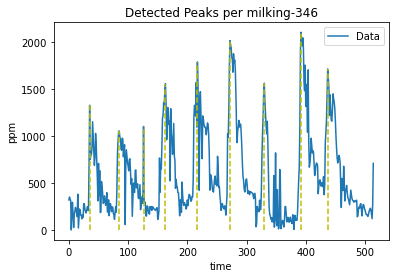

251
[  7  76 137 252 290]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

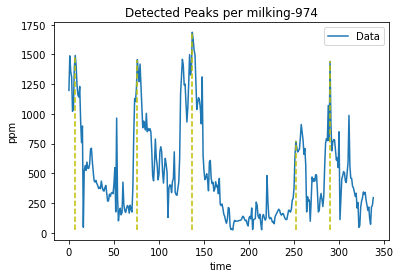

252
[  8  45  83 120 195 235 297]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

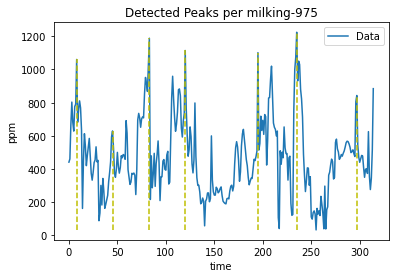

253
[  3  52 103 163 223 281 346]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

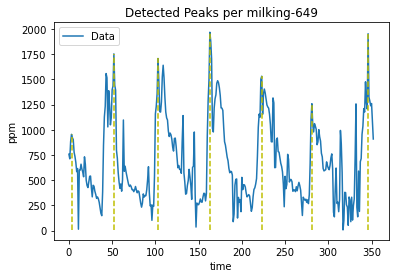

254
[ 21  72 122 158 209 248]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

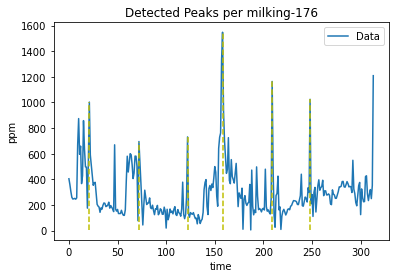

255
[ 16  81 144 200 256 315]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

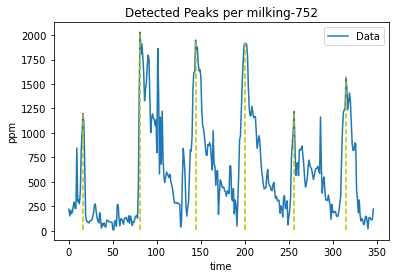

256
[ 12  70 127 196 271 325]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

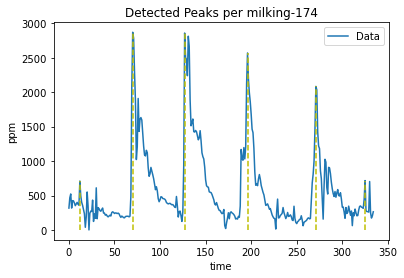

257
[104 141 196 243 307]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

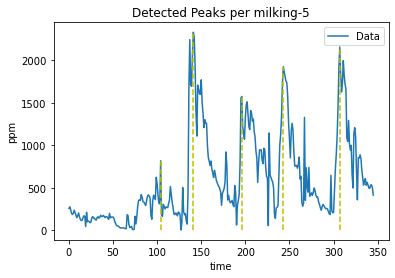

258
[ 19 108 182 247 306]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

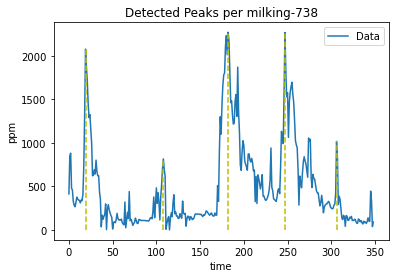

259
[ 27  90 153 220 267 347]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

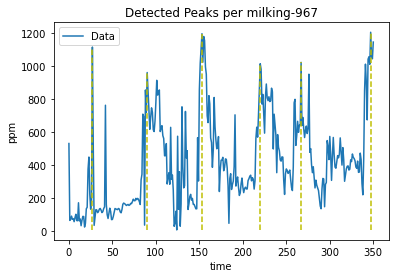

260
[ 13  77 141 191 227 328]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

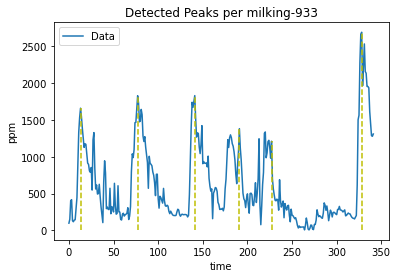

261
[ 17  78 130 182 246]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

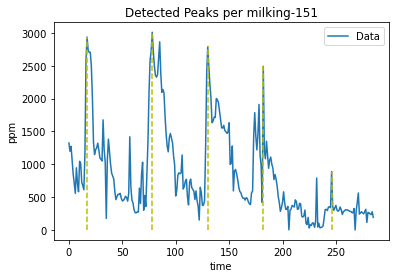

262
[ 27  70 137 204 246 282]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

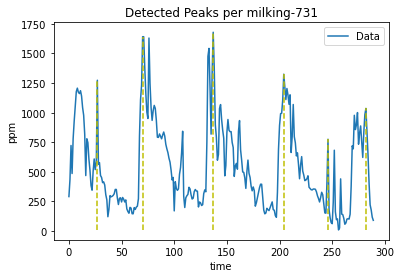

263
[ 15 117 183]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

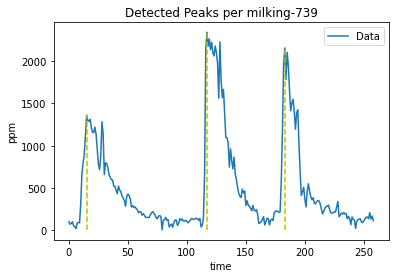

264
[ 63 109 177 254 313]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

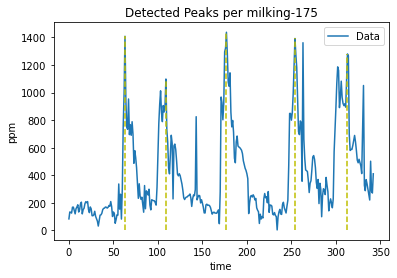

265
[ 26  88 177 228 272]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

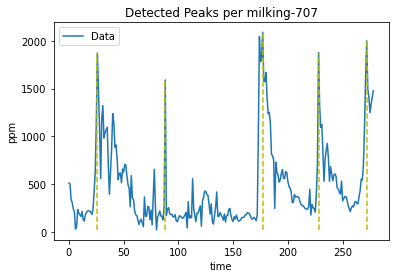

266
[  5  51 102 144 200 255]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

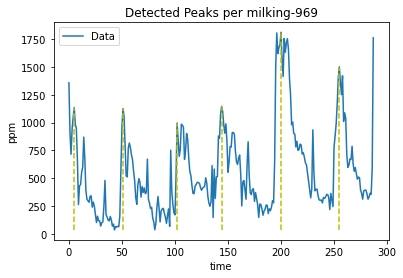

267
[ 29  68 126]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

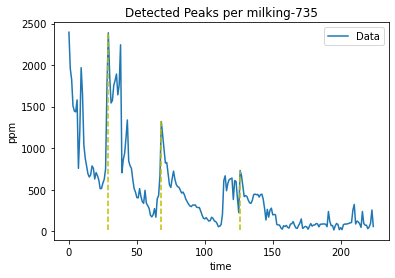

268
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123: 59, 12

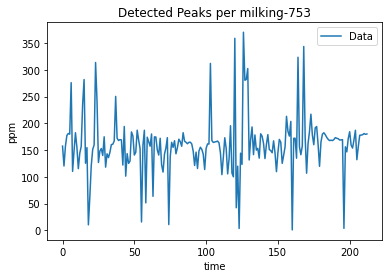

269
[ 28 127 215]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

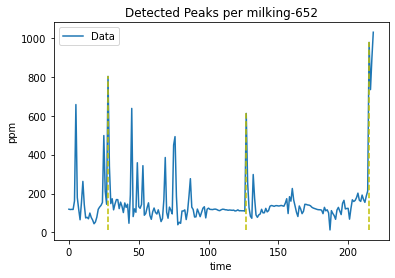

270
[  8  86 133 298]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

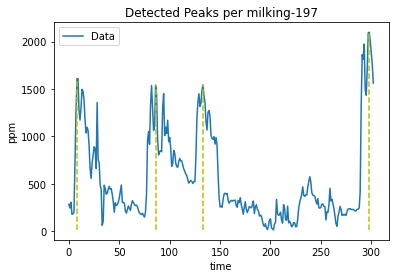

271
[ 12  66 107 146 194 231 280]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

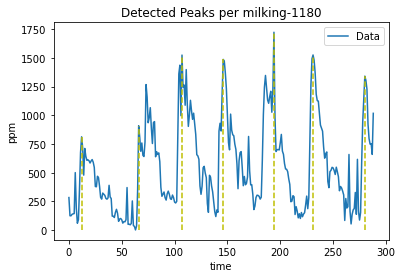

272
[ 38  77 152 222 291]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

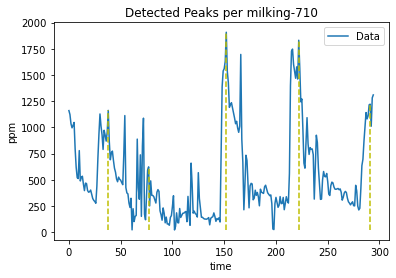

273
[ 13  69 106 144 221]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

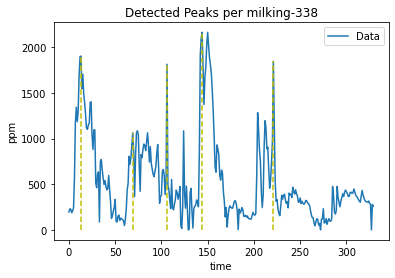

274
[ 26  62 104 175 237]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

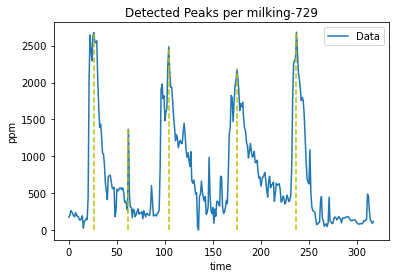

275
[ 51 101 153 211 279 329 392 471 541 598]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16,

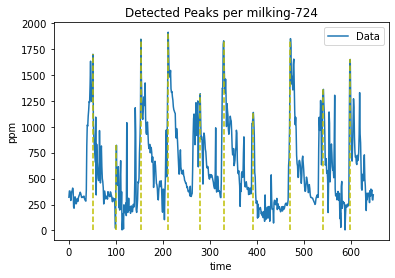

276
[ 33 122 158 195 241 299]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

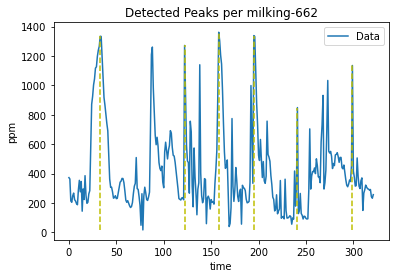

277
[ 22 114 173 240]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

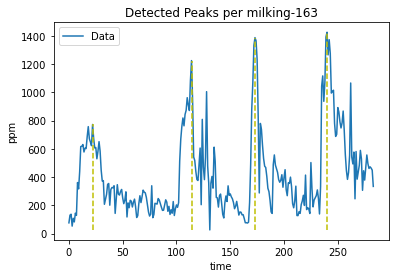

278
[ 27 134 197]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

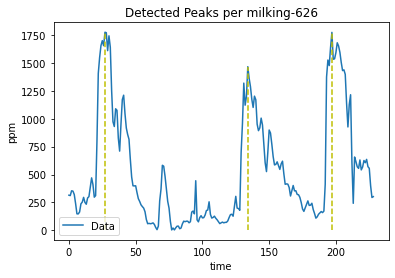

279
[ 40  96 188]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

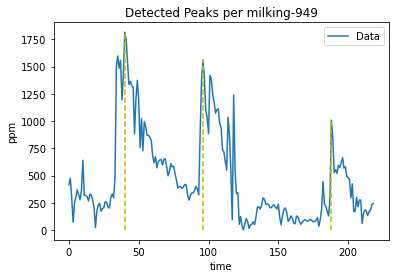

280
[ 15 123 201 283]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

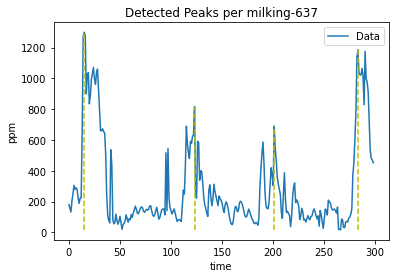

281
[ 17 114 165 204 278]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

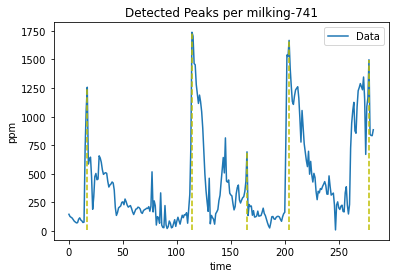

282
[ 28  83 119 154 209 249]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

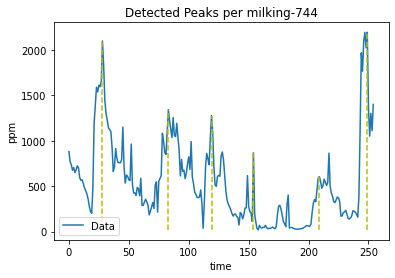

283
[ 20  80 145 190 245 300]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

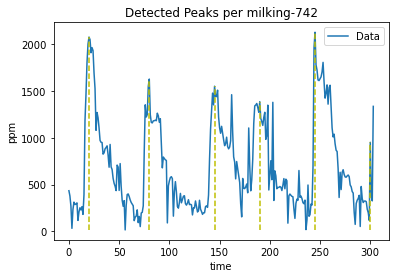

284
[109 150]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123:

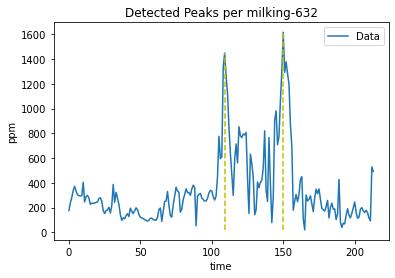

285
[ 42  83 137 201]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

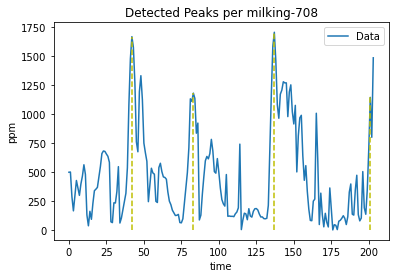

286
[ 14  74 131 170 218 273]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

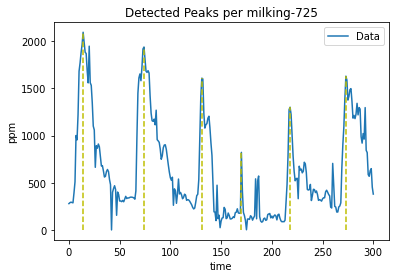

287
[ 29  70 105 141 181 233]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

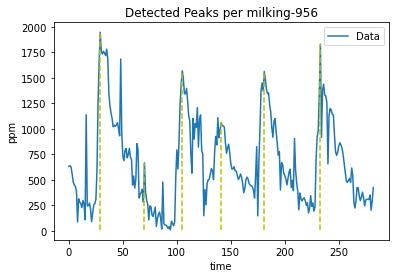

288
[  6  50  93 142 183 221]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

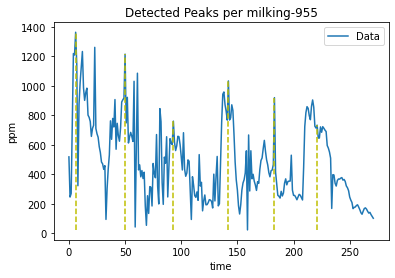

289
[ 42 110 165 225]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

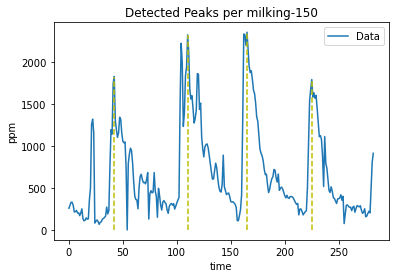

290
[  6  60 125 193 252 320]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

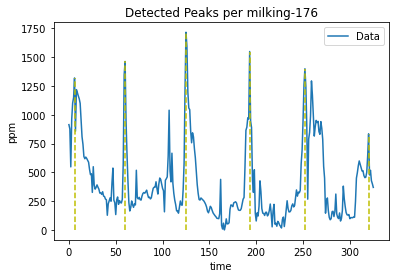

291
[ 16  65 106 174 248]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

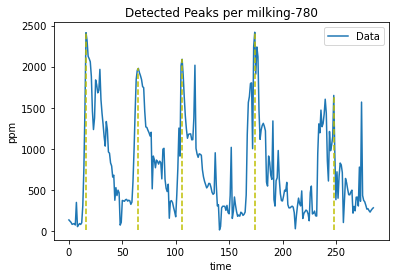

292
[ 17  58 100 136 240]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

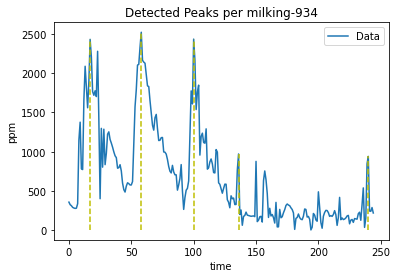

293
[  2  40  97 143 204 274 340]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

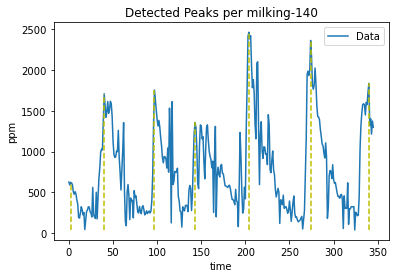

294
[  3  57 137 177 212 291]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

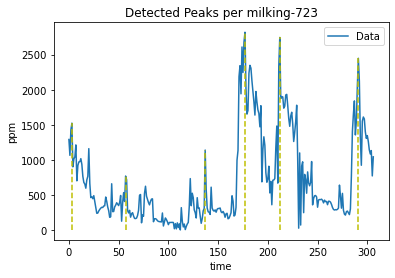

295
[ 27  69 112 148 210 249]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

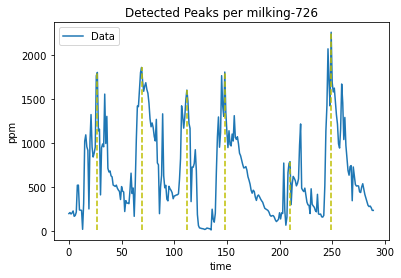

296
[ 18  67 125 169 205 253]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

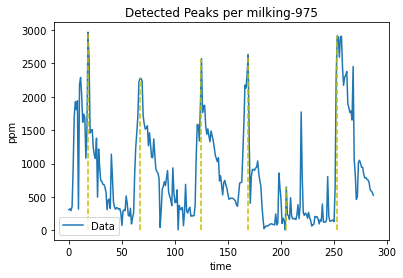

297
[ 21  97 174 271 341 379]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

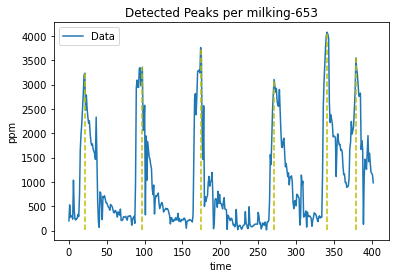

298
[ 29  85 136 220 263 327]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

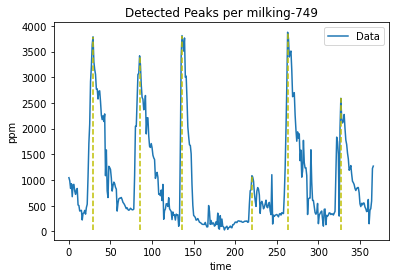

299
[  5  45  93 146 197 272]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

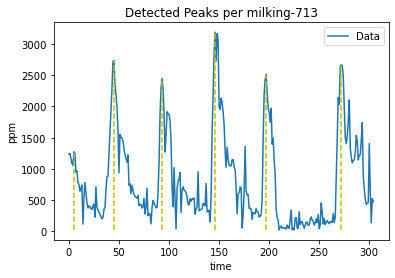

300
[  9  80 115 179 220 278 379]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

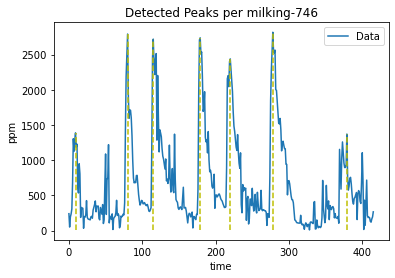

301
[ 15  51  87 137 173 221 264 323 363]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120

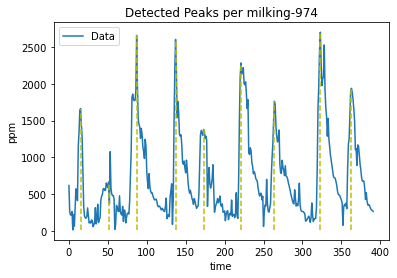

302
[ 25  68 110 193 252 310]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

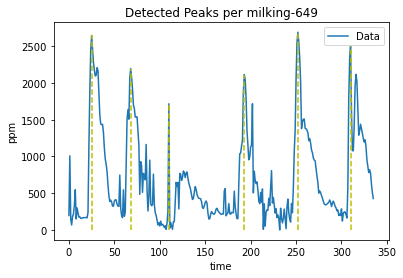

303
[ 33  69 168 206 261 318]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

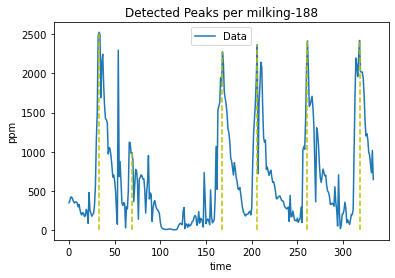

304
[ 21  71 123 173 239 276]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

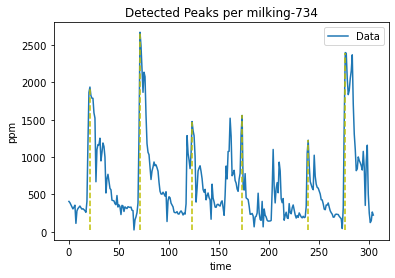

305
[  7  55 104 146 211]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

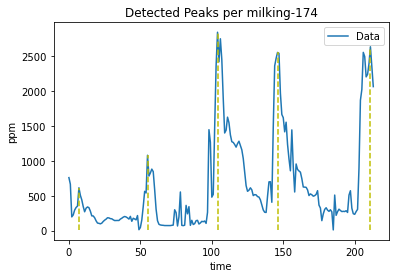

306
[ 33  94 144]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

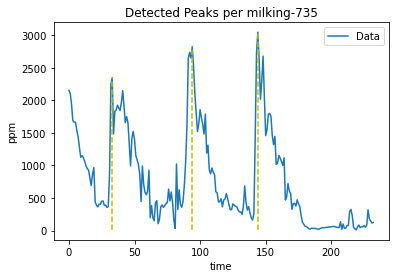

307
[ 26  84 159 220 255]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

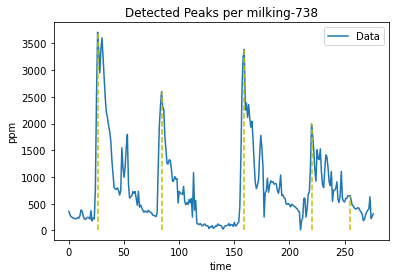

308
[ 14  77 136 197]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

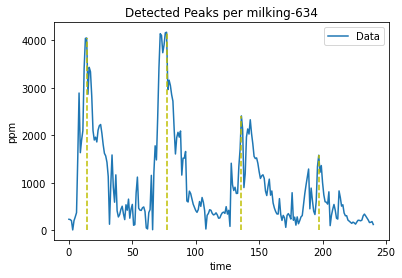

309
[ 50  91 152 202 256]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

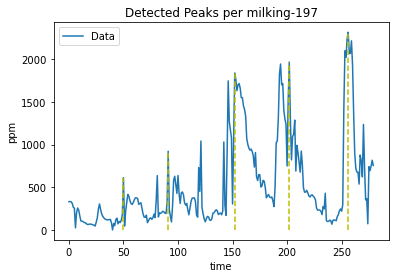

310
[ 19  90 132 199 260 308]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

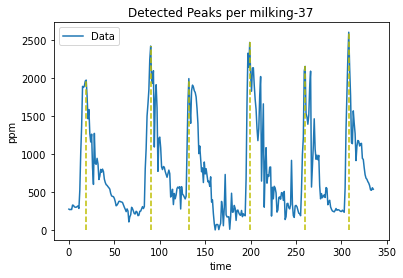

311
[ 37  79 218 280]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

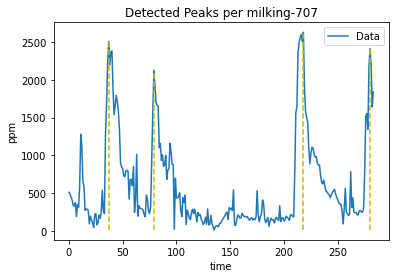

312
[  2  64 125 189 252]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

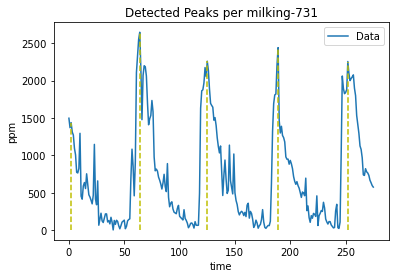

313
[  8 106 158 199 243]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

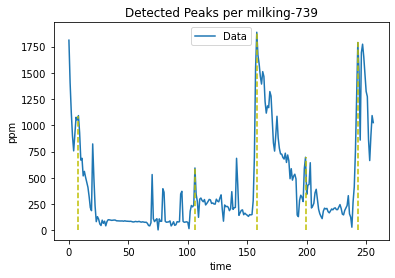

314
[ 50 116 168 232 283]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

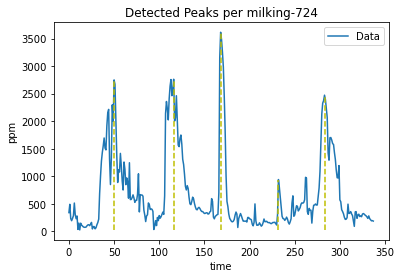

315
[  5  68 176 247]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

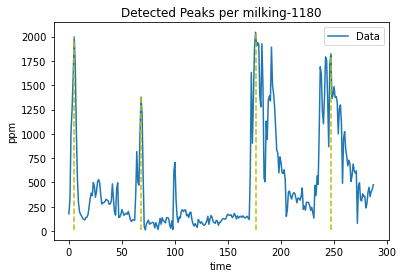

316
[  7  64 106 172 216]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

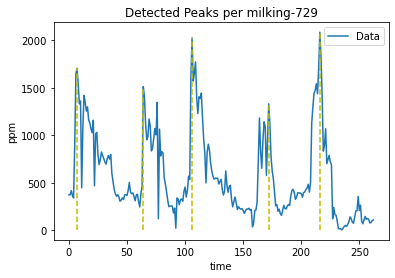

317
[  2  45  86 142 178 236 279 328 389]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120

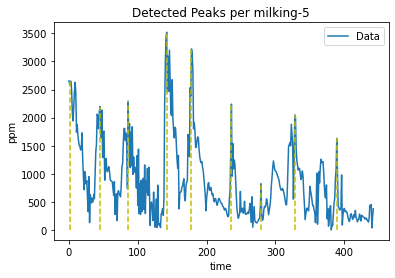

318
[ 46 155 221 290 325]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

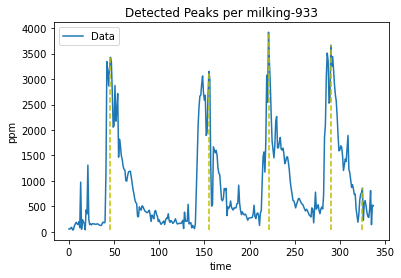

319
[  9  74 164 251 293]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

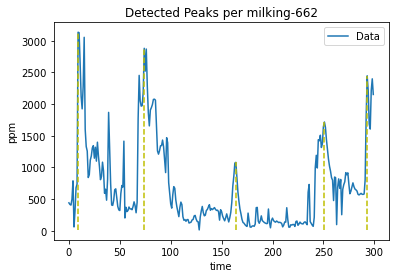

320
[  9  84 123 181 221 258 310]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

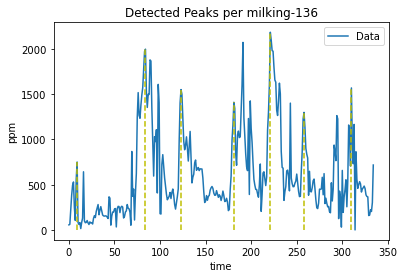

321
[  3  42  87 122 174 332]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

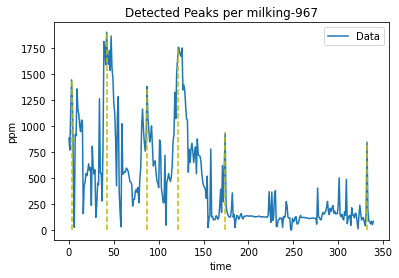

322
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123: 59, 12

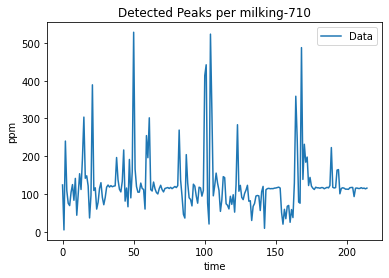

323
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123: 59, 12

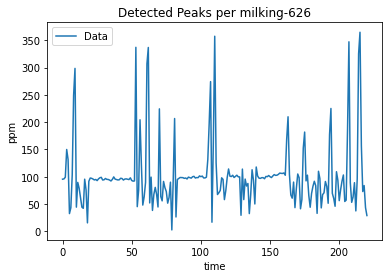

324
[ 48  91 201 259 331 400]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

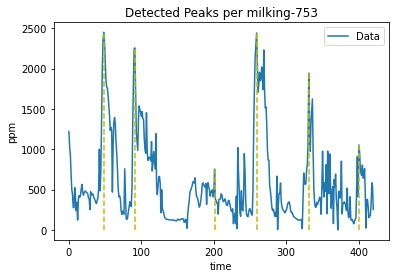

325
[ 19  55  95 138 197 253 322 374]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

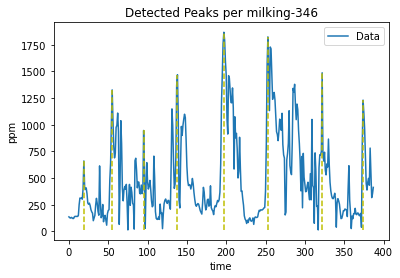

326
[ 17  65 126 172 212 253 312 380]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

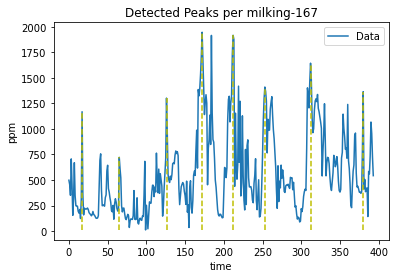

327
[ 30  67 171 218]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

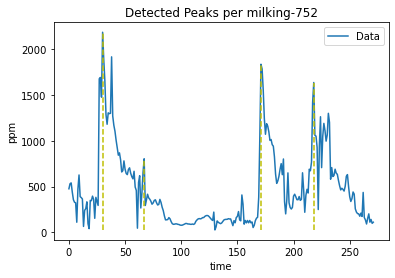

328
[ 14  54 108 165 222 273]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

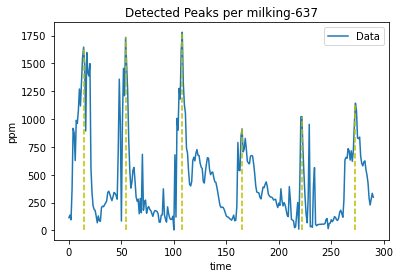

329
[ 32  94 141 189 226 267 315 356 402 457]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16,

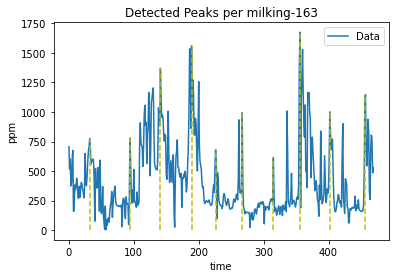

330
[ 27  98 144 206]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

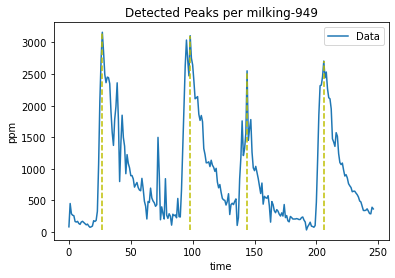

331
[  1  51 114 201]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

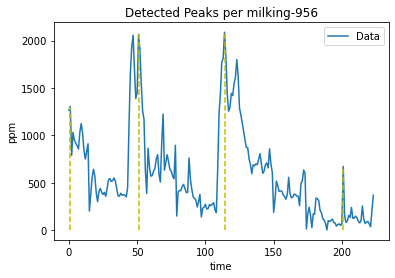

332
[ 14  88 162 234]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

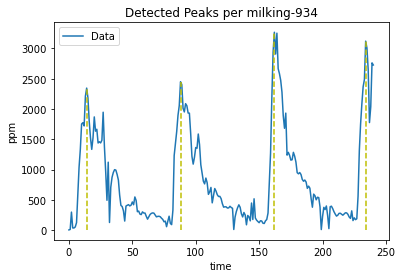

333
[ 19  55 105 141 181 221 257 314]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

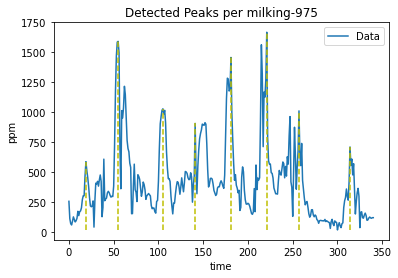

334
[ 40  87 168 232 268]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

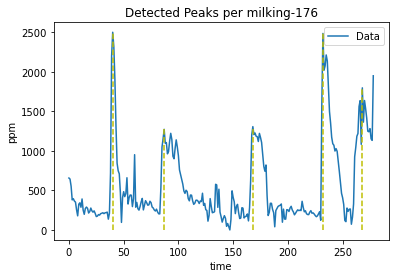

335
[ 29  88 148 224]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

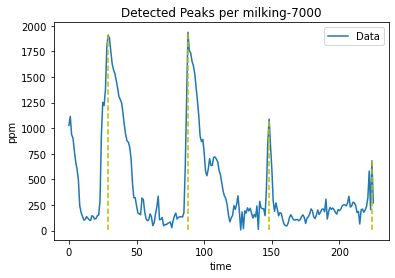

336
[ 14  78 158]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

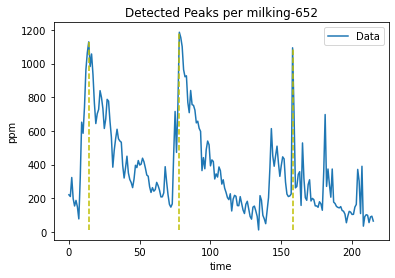

337
[ 26  90 157 194 257]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

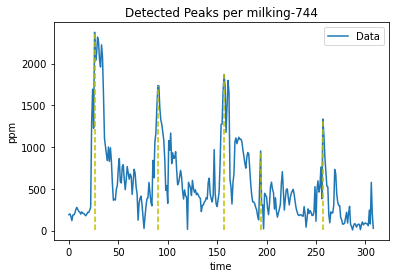

338
[ 45  87 144 210]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

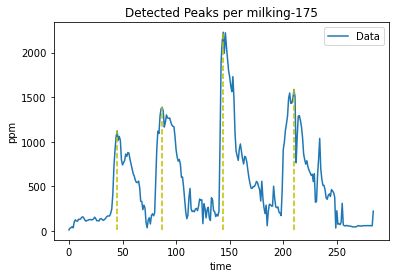

339
[  5 126 161 224 302]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

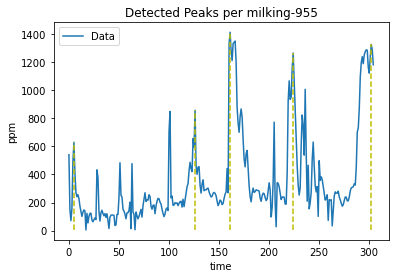

340
[ 25 122 197 247]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

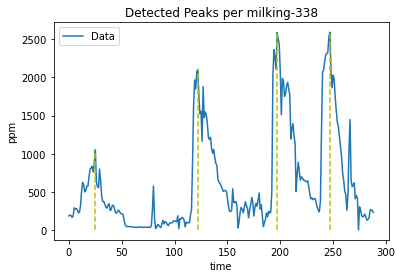

341
[ 21 126 234 273]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

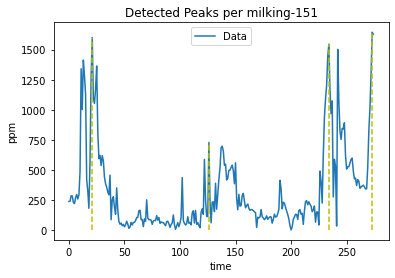

342
[  3  74 116 231 289]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

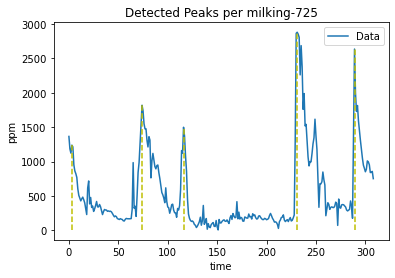

343
[ 77 140 235]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

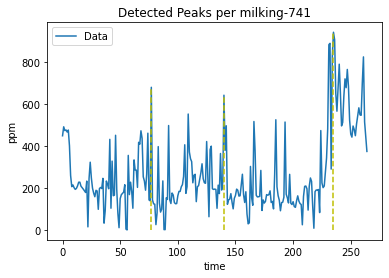

344
[  8  72 114 175 234]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

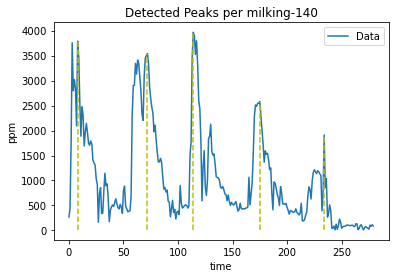

345
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123: 59, 12

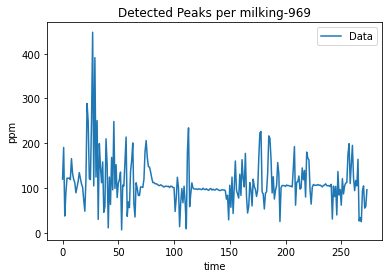

346
[163 231]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123:

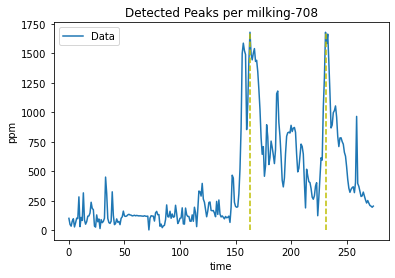

347
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123: 59, 12

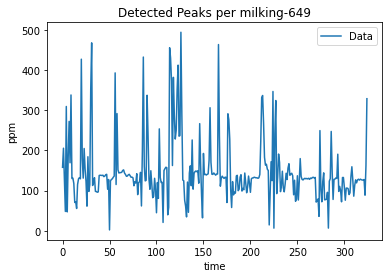

348
[  7  79 135 200 235]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

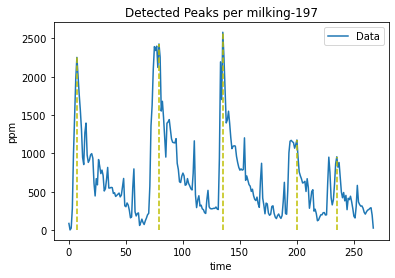

349
[ 22  82 122 183 218 280 319]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

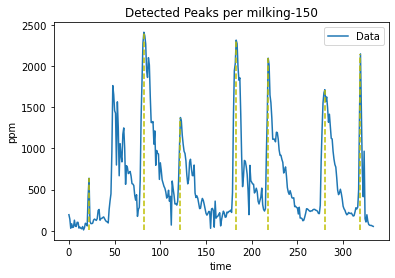

350
[ 73 136 204 264 310]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

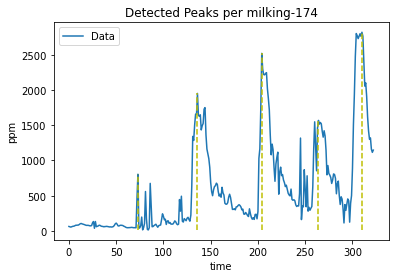

351
[ 39  91 155 215]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

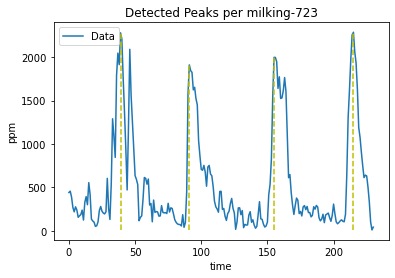

352
[ 70 136 215]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

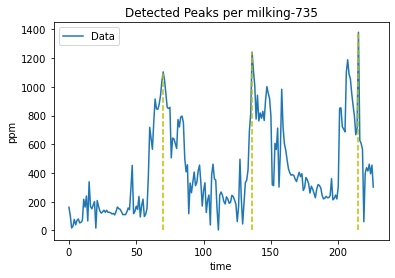

353
[  2  38  73 189 255 293]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

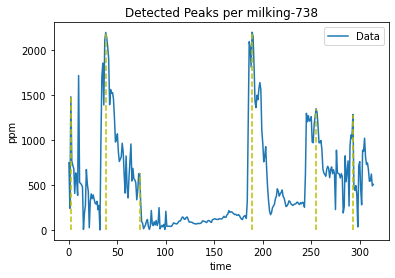

354
[  9  46 139 175 210 276]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

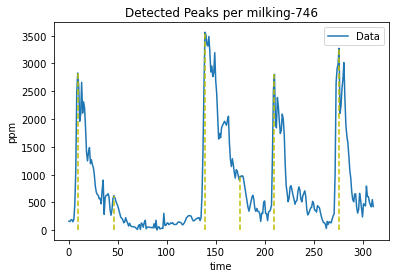

355
[  1  39 105 193 251 291]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

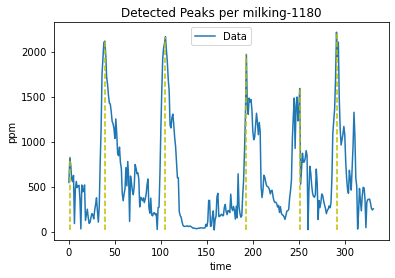

356
[  9  45 108 148 185 226]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

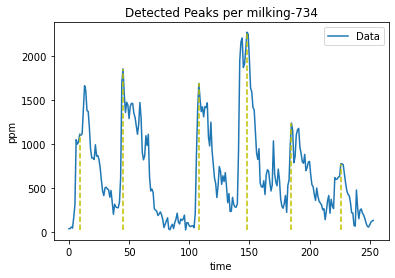

357
[ 44 114 181 247]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

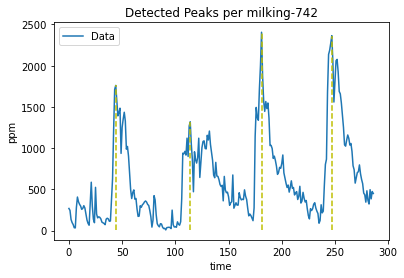

358
[ 33  89 184 226]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

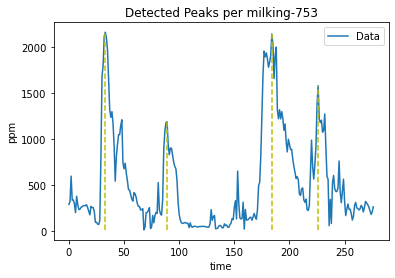

359
[ 20  84 177 222 282]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

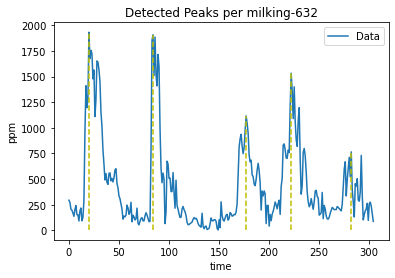

360
[ 41 119 224 266 323]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

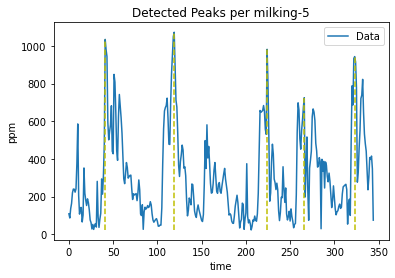

361
[  4  65 197 239 290 325 364 432 502]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120

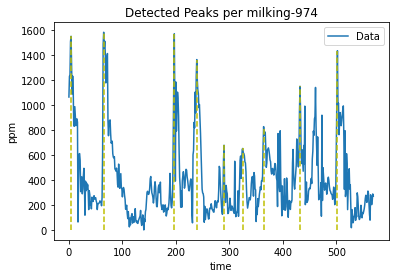

362
[ 29  86 142 207]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

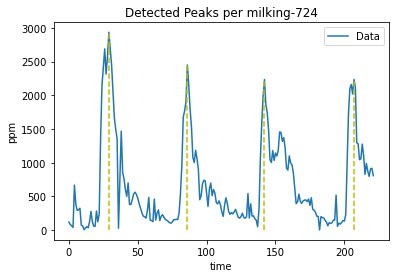

363
[  4  42 183 246]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

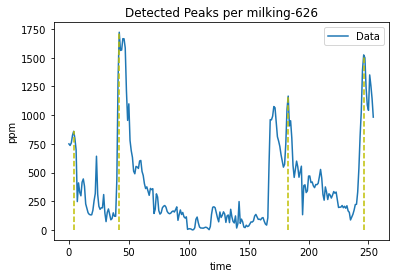

364
[124 176 240]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

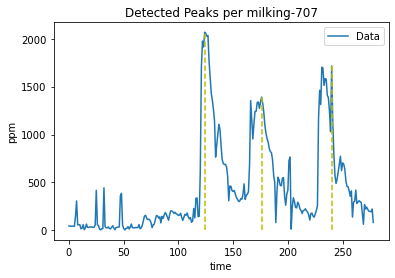

365
[ 22  65 132 179 256 291]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

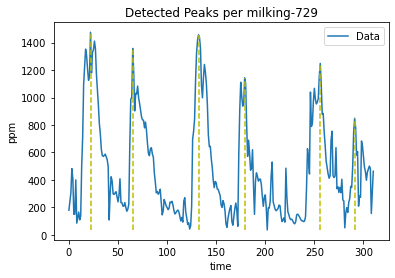

366
[ 54 123 166 226]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

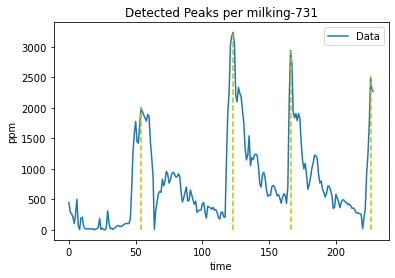

367
[  5  55 103]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

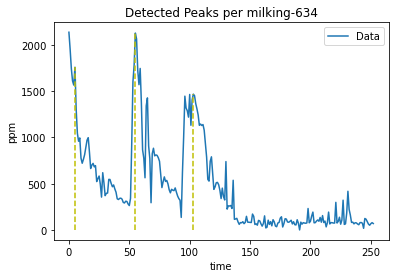

368
[ 21  90 156 226 291 387 453 529]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

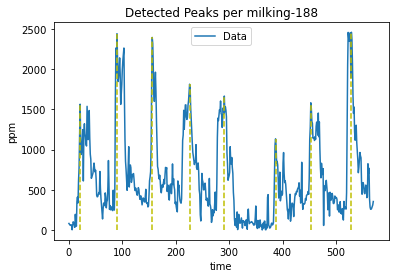

369
[ 22  89 146 235 294]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

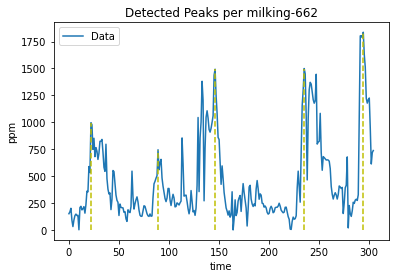

370
[  9  55  96 148 310]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

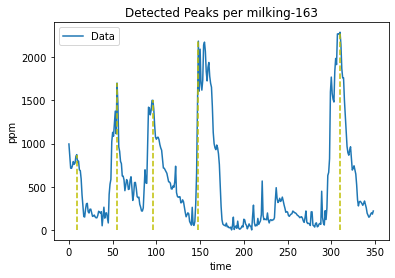

371
[ 16  54 113 167 210 274]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

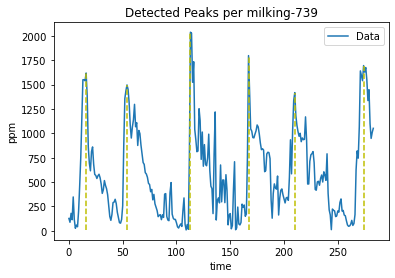

372
[  3  66 103 204]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

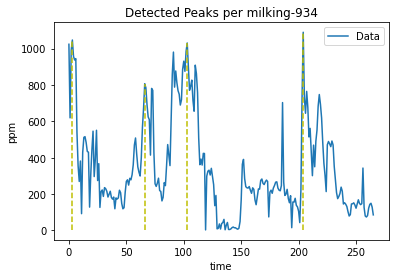

373
[ 4 43 79]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123

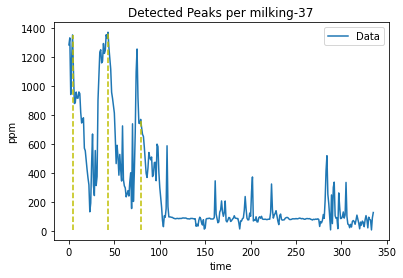

374
[139 174 215 277]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

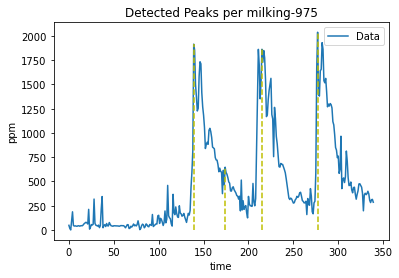

375
[ 21  83 165 239 274 312]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

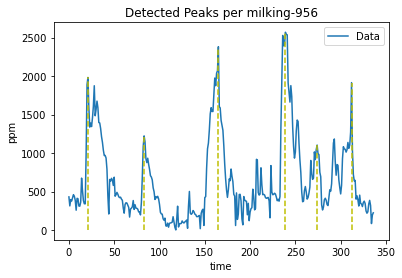

376
[ 30  95 158 219 279]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

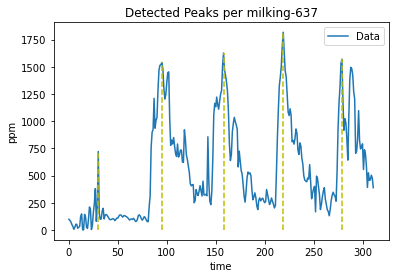

377
[ 33 128 180 218 275 311 373]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

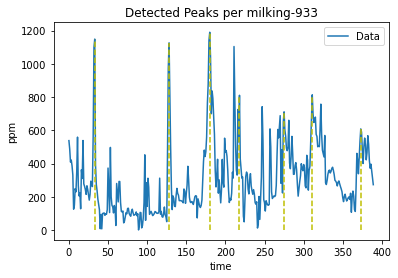

378
[ 82 125 163 204 239]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

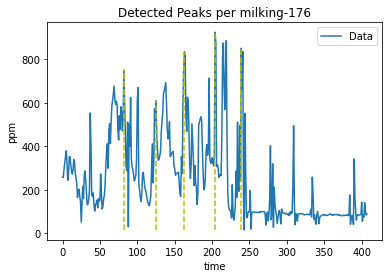

379
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123: 59, 12

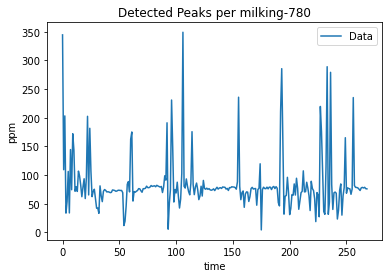

380
[150 208 243]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

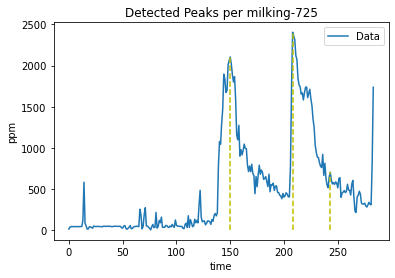

381
[13]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123: 59, 

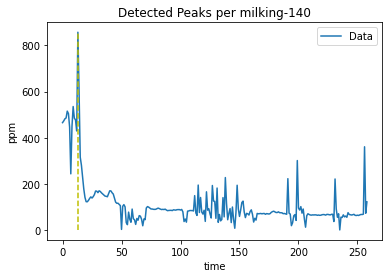

382
[175 236]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123:

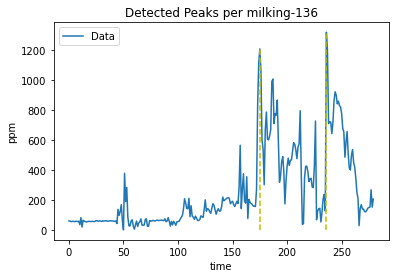

383
[ 20  55  90 209]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

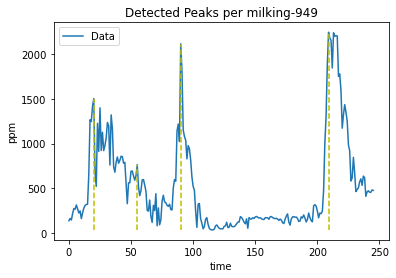

384
[ 95 138 184 246 281]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

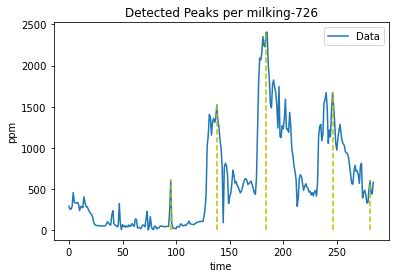

385
[ 10  76 113 170 211]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

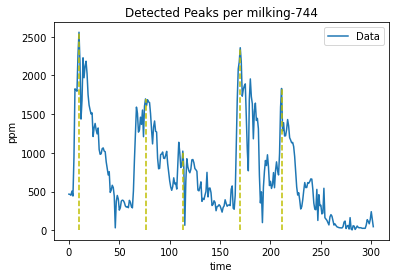

386
[ 18  88 165 244 284]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

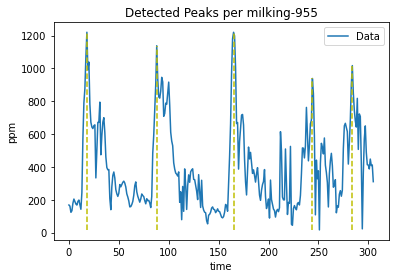

387
[ 89 184 236]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

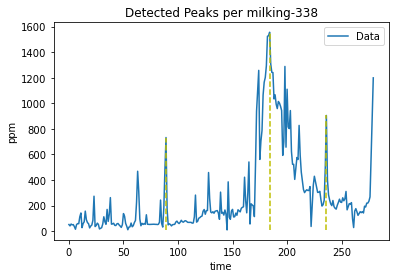

388
[  6  68 166 231]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

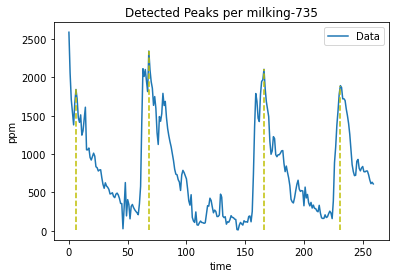

389
[  7  53  93 149 200 254 330]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

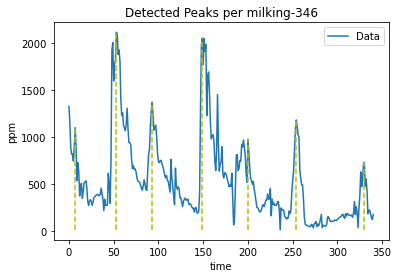

390
[ 20  61 112 274]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

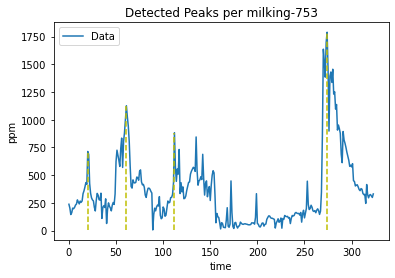

391
[  3  45 127 175]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

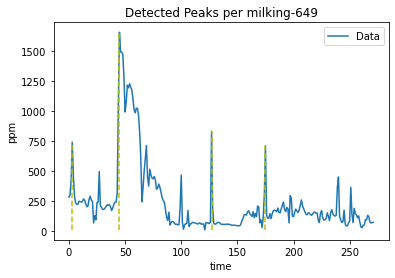

392
[ 18  87 167 211 258 298]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

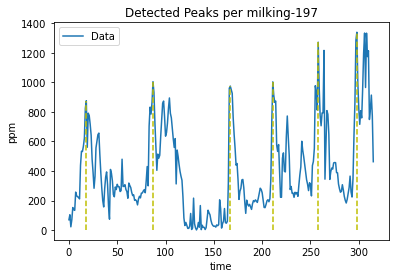

393
[ 17  68 109 220 286]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

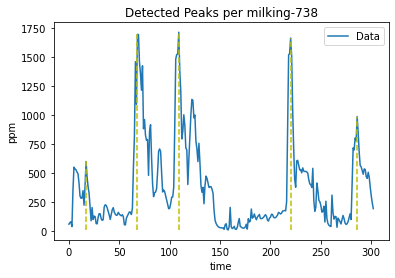

394
[ 10  69 108 156 200 256 293 366]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

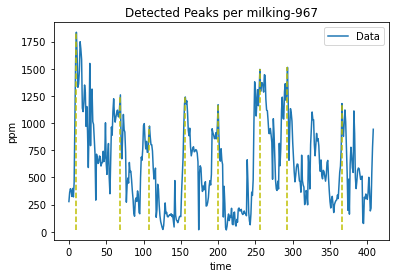

395
[  4  59 106 153 221 291]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

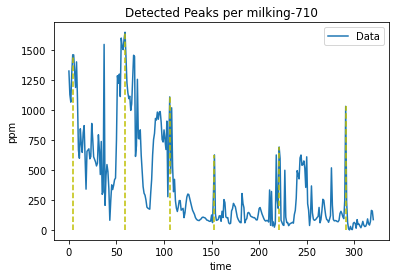

396
[ 11  61 103 146 193 235]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

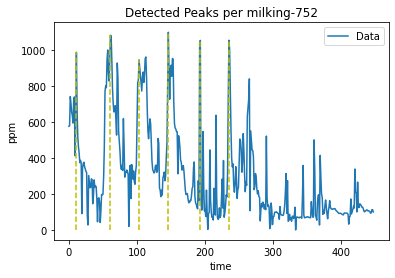

397
[ 46  89 156 226]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

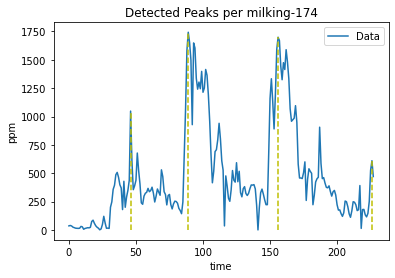

398
[ 48 115 197]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

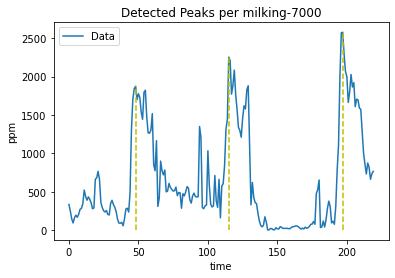

399
[ 35  97 178 234]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

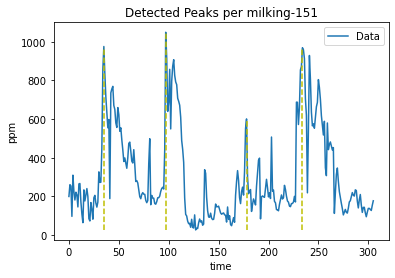

400
[123 185 227]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

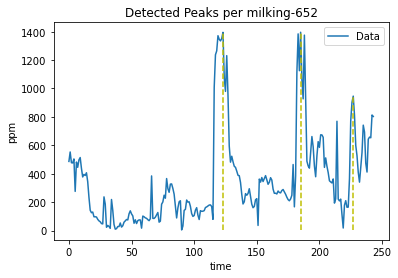

401
[ 11  53 121 199 264]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

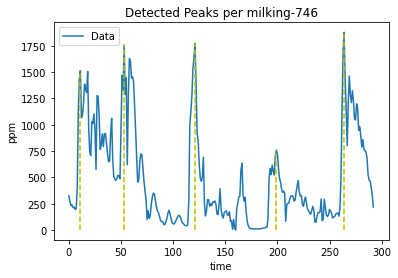

402
[ 32  87 146 203]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

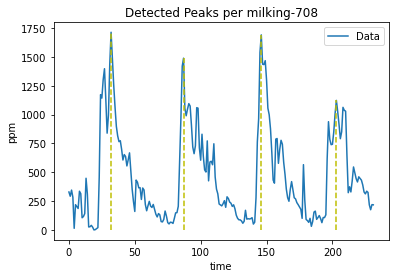

403
[  8  58 103 142 274 332 398 451]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

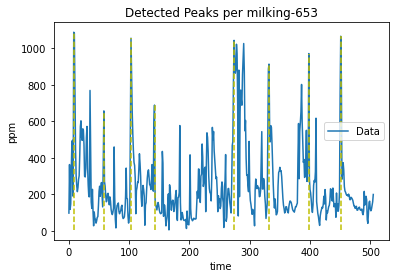

404
[ 50 107 185 287]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

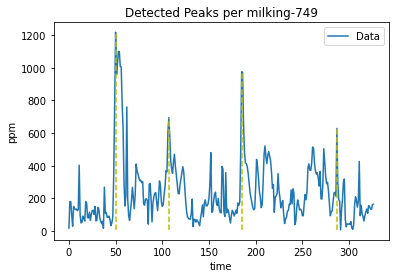

405
[ 17  98 156 232 296]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

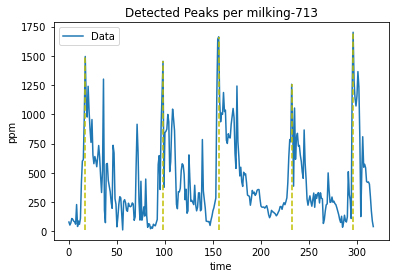

406
[ 69 108 144 184 235 280]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

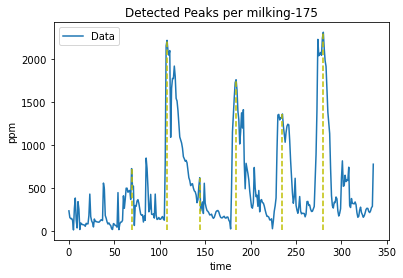

407
[  2  47  91 135 208]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

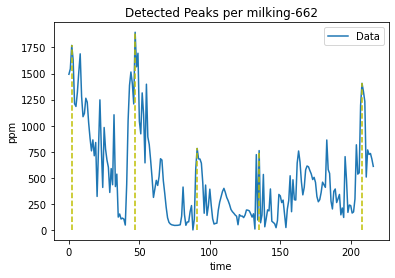

408
[  6  53 101 150 190]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

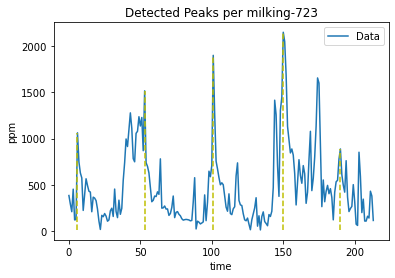

409
[ 15  83 169 243 305 380 417]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

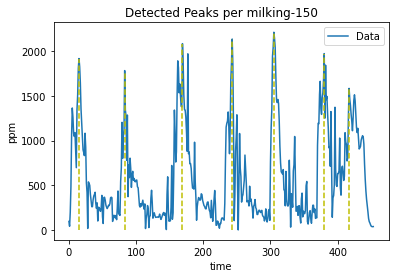

410
[ 50 115 166 238 305 344]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

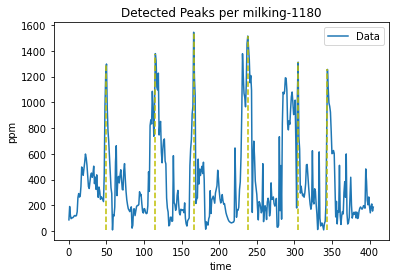

411
[  3  46 206 241 316 351 422]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

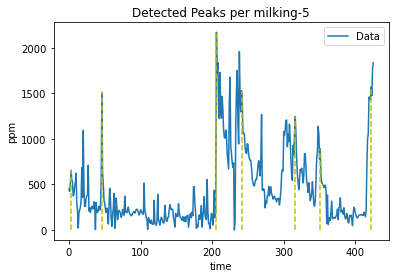

412
[ 34 114 180 229 267 322]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

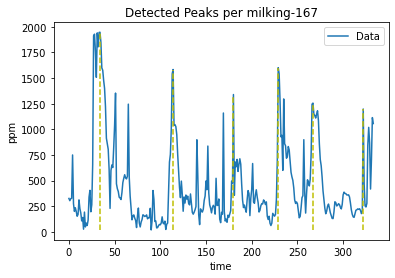

413
[ 26  73 117 192 260]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

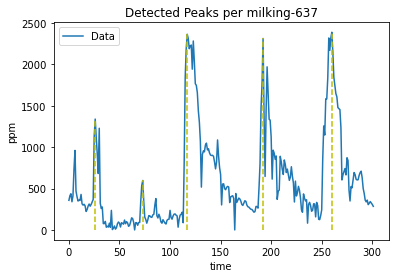

414
[ 30  88 139 182 263 332 409 471]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

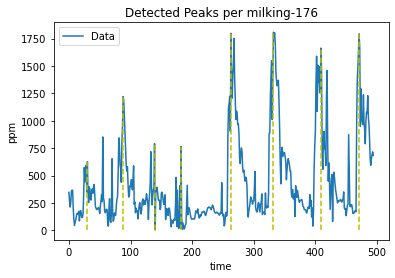

415
[ 29  71 107 232 268 306 372]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

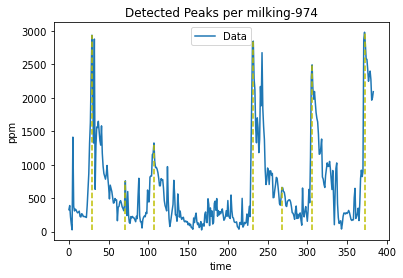

416
[  8  57 100 168 228 282 357]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

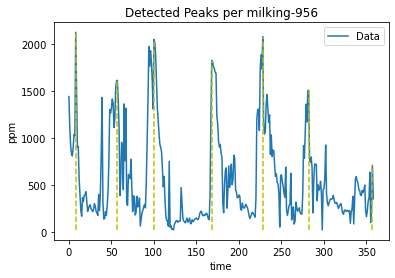

417
[ 18  91 185 226 264 314 414]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

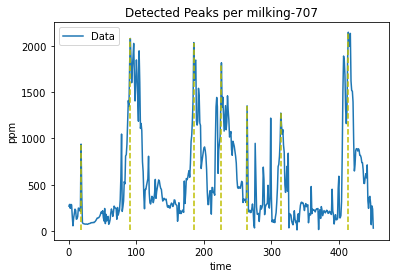

418
[  3  38  94 134 185 228]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

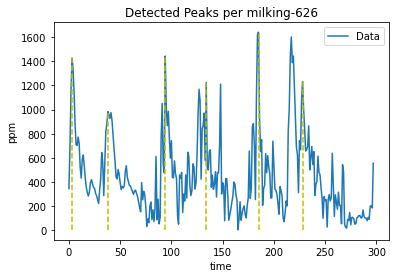

419
[ 73 133 198 240 279]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

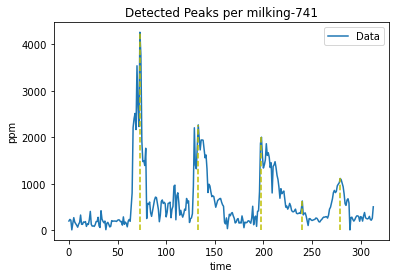

420
[  3  79 117 152 211 248 290]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

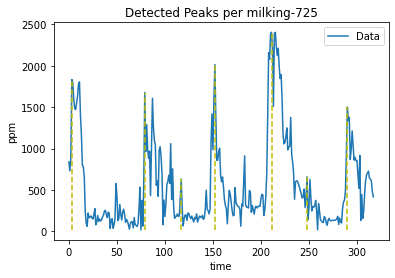

421
[  4  43 108 165 237 274 330 374]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

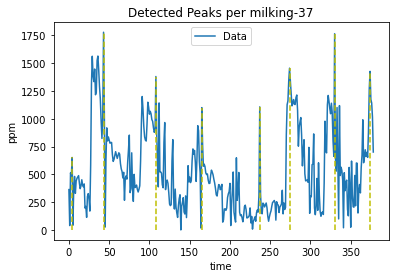

422
[  4  66 127 215 286 327]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

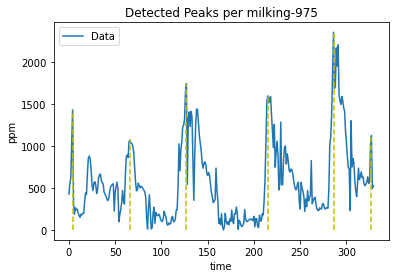

423
[ 30  74 119 187 262]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

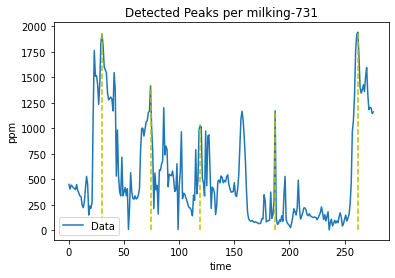

424
[  8  55 121 185 244 279]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

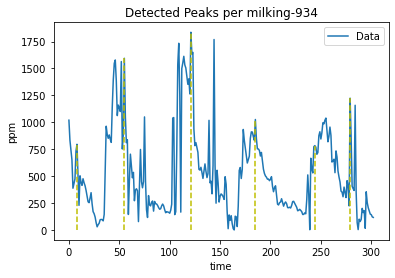

425
[  5  50 102 162 215 264 319]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

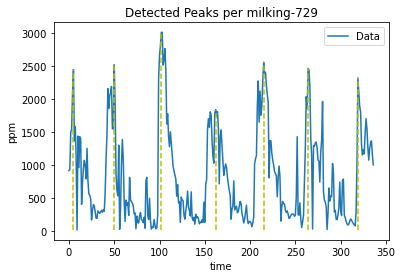

426
[ 26  65 107 157 201 264 300]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

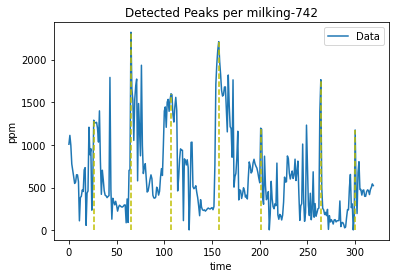

427
[ 29  67 143 209 269 337 383]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

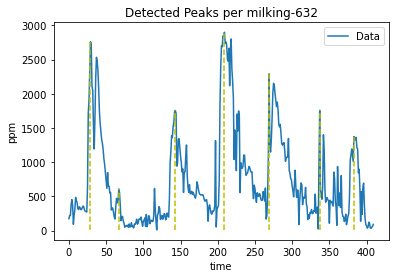

428
[ 81 152 191 227 304]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

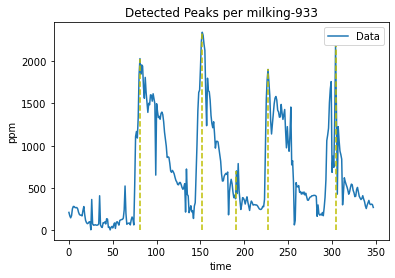

429
[ 12  65 113 155 197 245 303]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

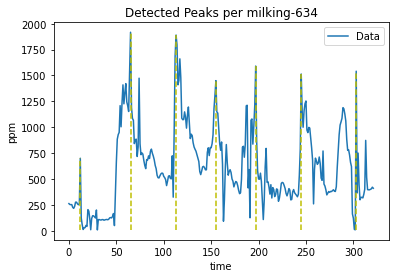

430
[ 23  82 160 196 254]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

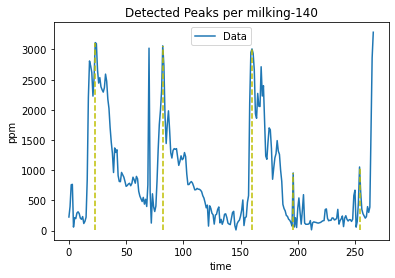

431
[  8  68 114 150 268 305]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

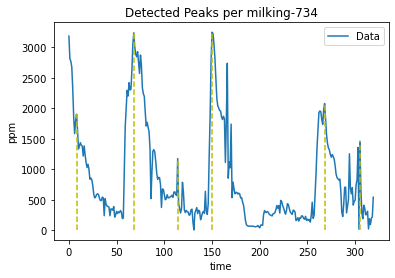

432
[ 22  61 106 163 209 282 346 385 427]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120

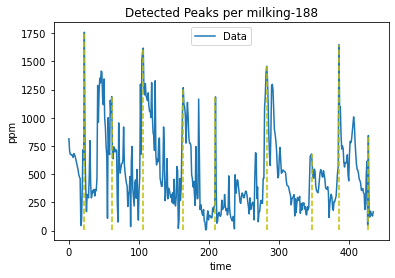

433
[ 36  75 118 161 206 243 378 435 497 546 603]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119:

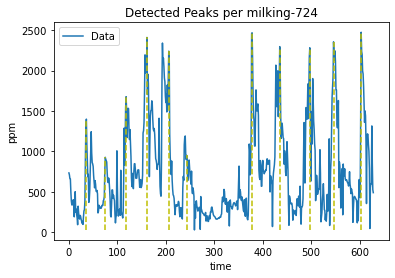

434
[ 22 104 141 180 227]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

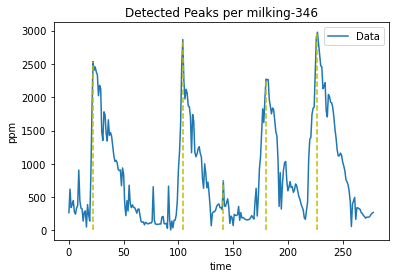

435
[  8  67 143 184 239 302]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

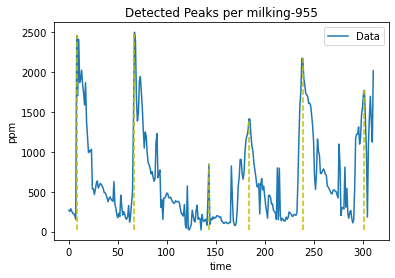

436
[ 32  80 129 169]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

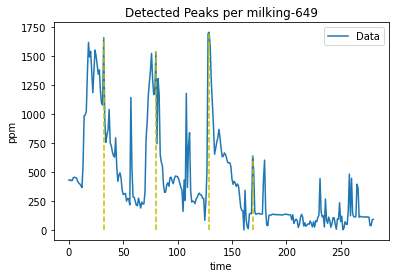

437
[  5  74 132 194]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

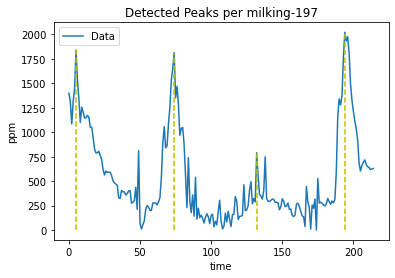

438
[ 20  86 140 191 230]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

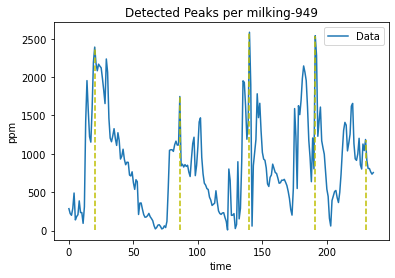

439
[ 76 136 193 255]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

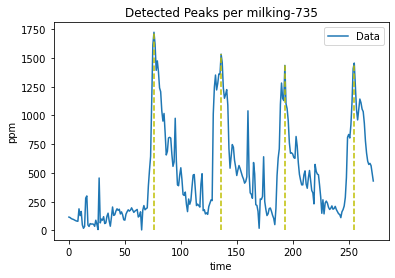

440
[  7  66 102 138 184 251 336 380 426]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120

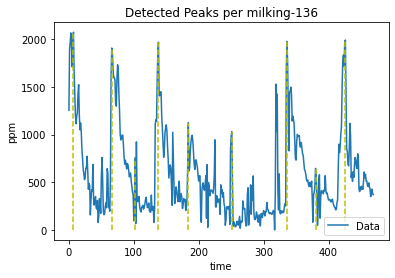

441
[ 25  73 115 158 201 241 354]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

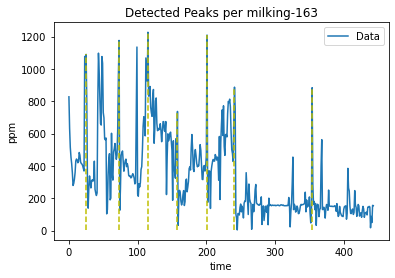

442
[ 66 247 294]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

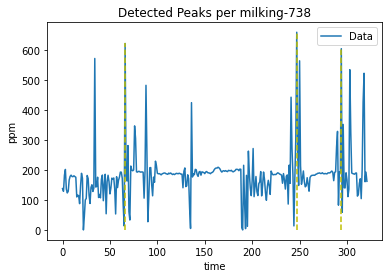

443
[ 25 119 161 211 260 299]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

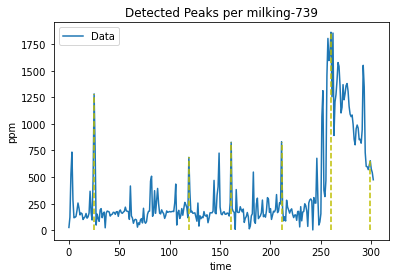

444
[ 11  51  87 150 219 310 368]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

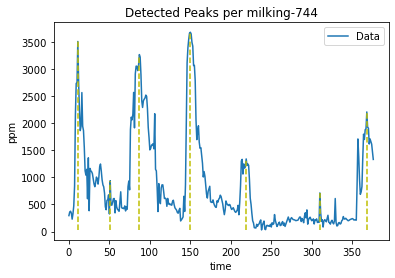

445
[  9  56 118 162 225 271 336]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

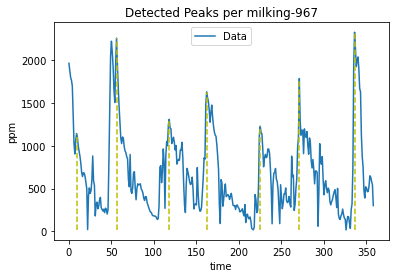

446
[ 16  71 124 160 198 239 291]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

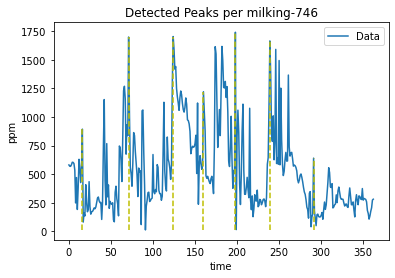

447
[ 44  80 131 192 258 320]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

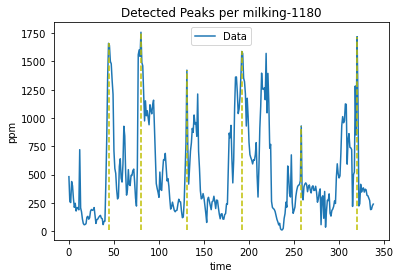

448
[ 25  62 115 150 212 260 295]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

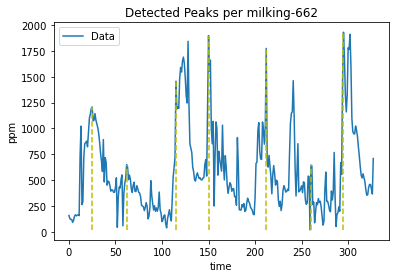

449
[ 11  51  88 139 208 259 325]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

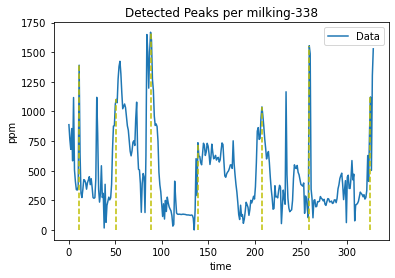

450
[  1  40 130 180 251 313]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

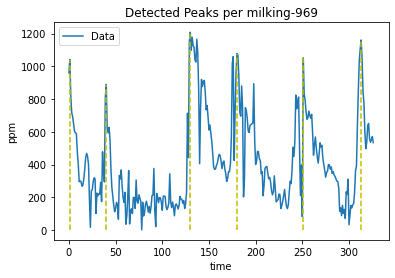

451
[ 21  74 126]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

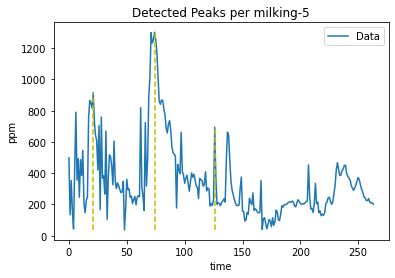

452
[  7  72 141 196 251 313]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

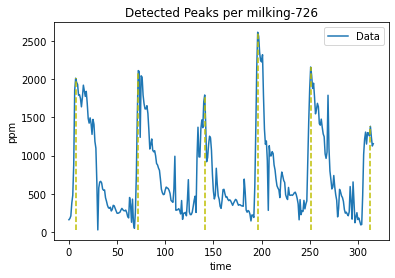

453
[  8  61 119 185 246 309 412]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

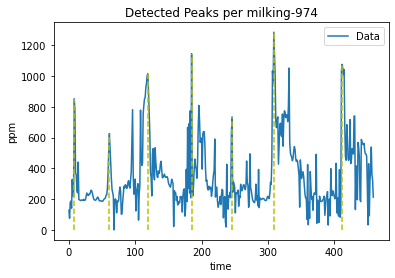

454
[ 32  71 120 200 245 310]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

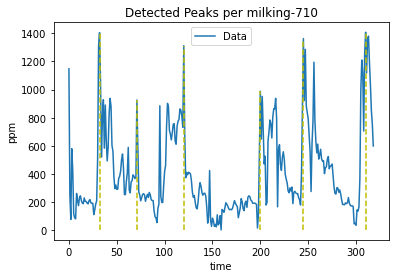

455
[ 11  65 100 195 241 309 359]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

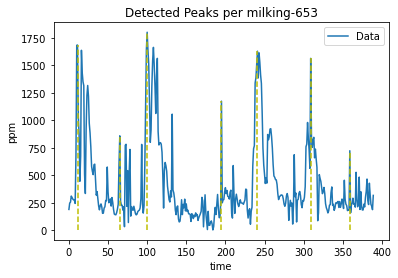

456
[  8  60 215 257 294]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

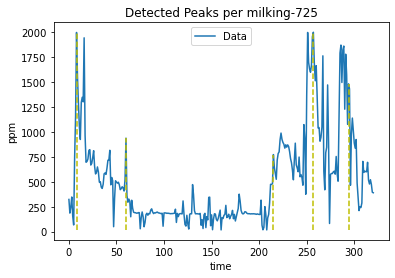

457
[ 53 114 169]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

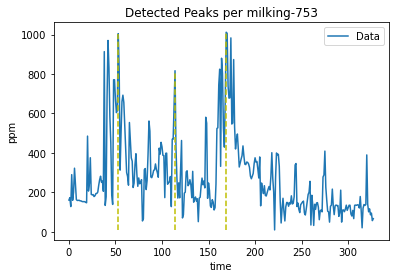

458
[  6 122 226 267 304 347]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

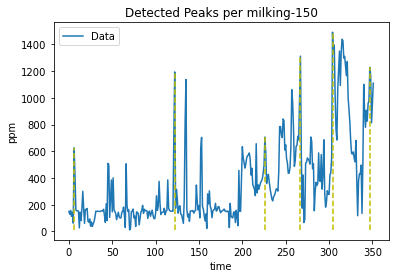

459
[ 32  86 155 200 255 291 337]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

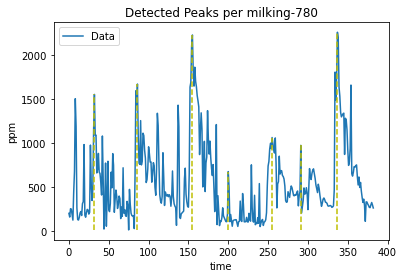

460
[ 13  77 206 248 313]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

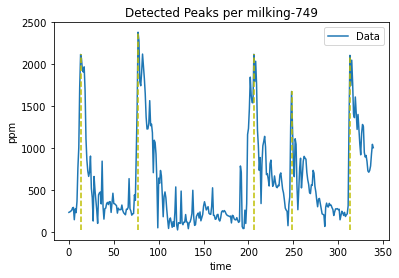

461
[ 53 104 144 213]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

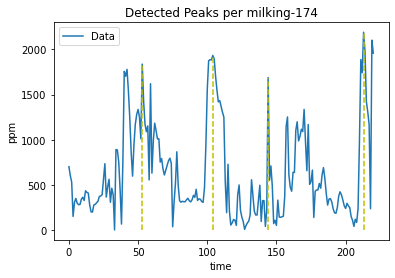

462
[  4  44 110 155 208]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

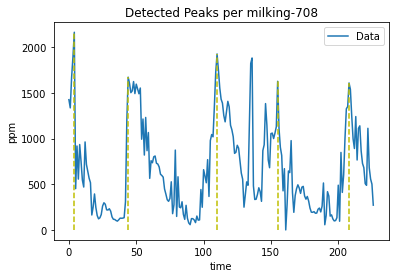

463
[ 33 100 139 195 281]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

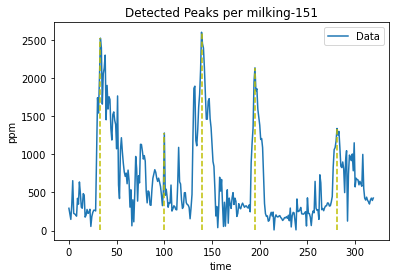

464
[ 16  51 108 160 228]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

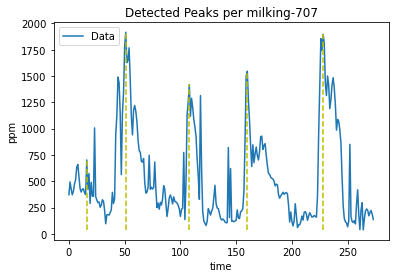

465
[  2  60  97 138 186 235]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

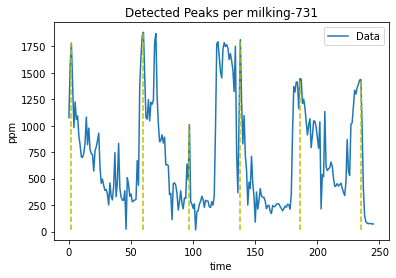

466
[  3  71 141 201]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

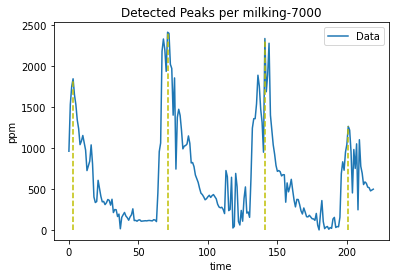

467
[ 38  91 173 232 283 337]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

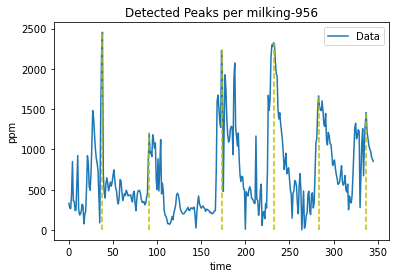

468
[ 26  96 136 196 254 314]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

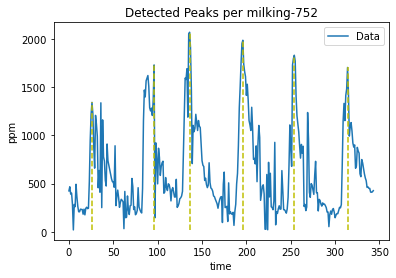

469
[ 53 104 158 197 249]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

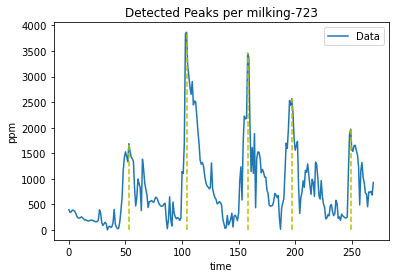

470
[ 32  87 129 167 202 268 303]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

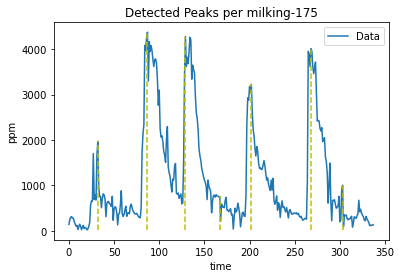

471
[  5  62 126 184]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

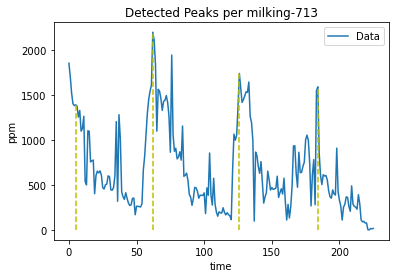

472
[ 51  86 130 167 227]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

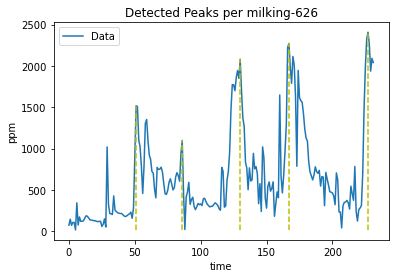

473
[  9  70 108 165 207 290 338]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

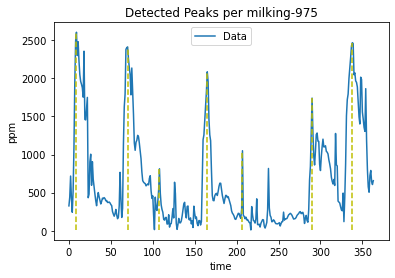

474
[ 32  85 134 172 229 273]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

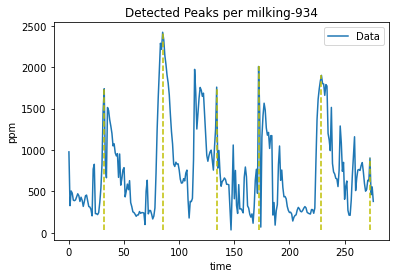

475
[ 13  75 151 228 279 323 380 441]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

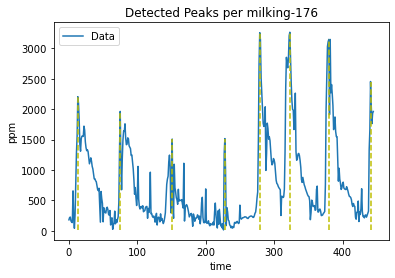

476
[  3  55  92 128 182 222 272 325]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

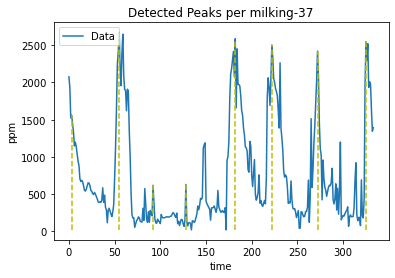

477
[ 29  71 106 198 260]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

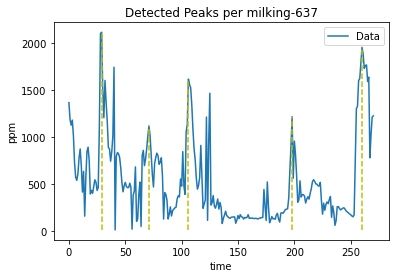

478
[ 29  88 125 183 230]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

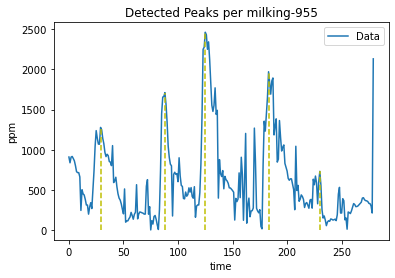

479
[  3  99 155 205 277]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

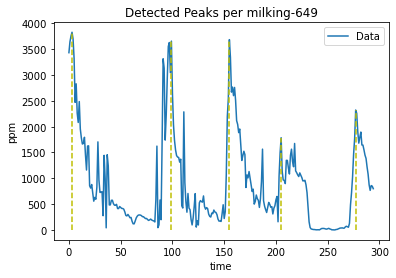

480
[ 20  71 113 158 218 279 323]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

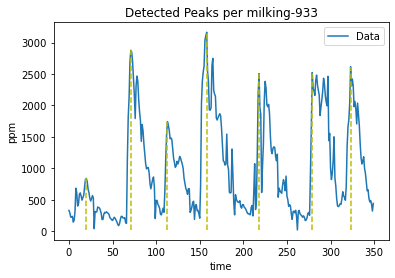

481
[ 17  76 119 171]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

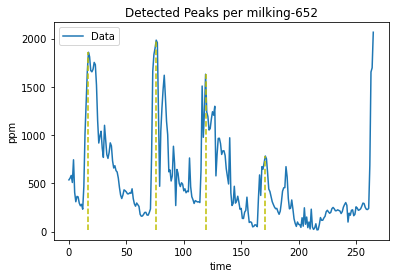

482
[ 34  90 129 195 239 281]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

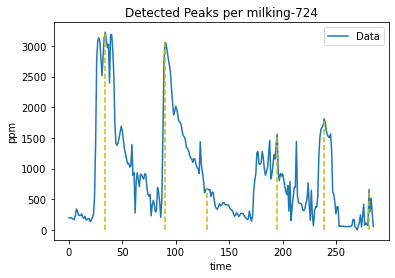

483
[  5  54  96 149 188 223 276]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

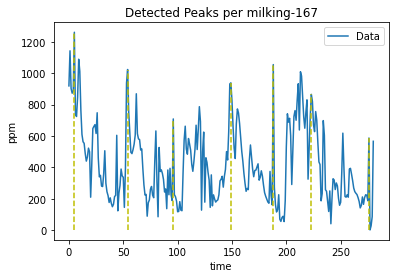

484
[  8  75 131 198 262]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

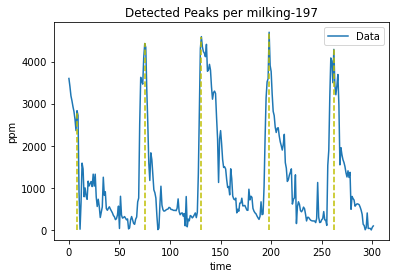

485
[ 24  64 132 195 257]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

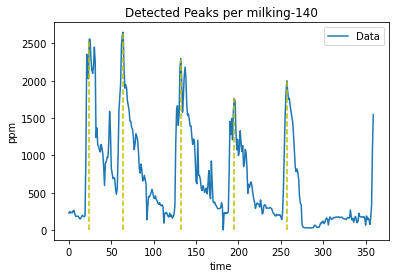

486
[  6  79 169 212 249]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

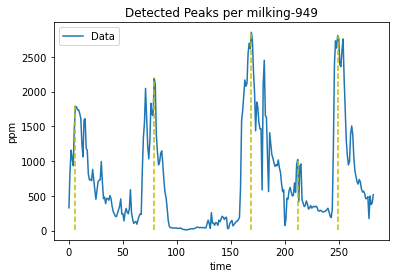

487
[  5  61  96 134 202 255 303]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 12

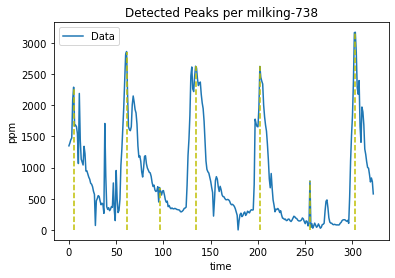

488
[ 48 117 172 237 305]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

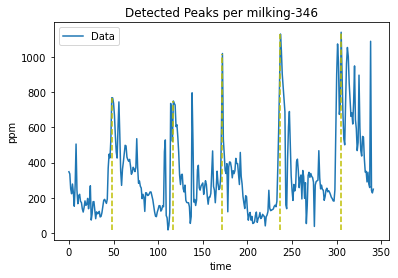

489
[ 31  95 258 307]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

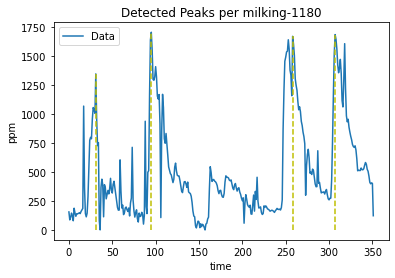

490
[ 23  91 238 280]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

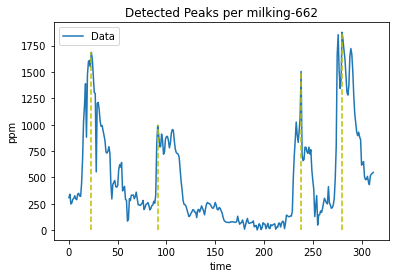

491
[  5  48 122 159 263 298]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

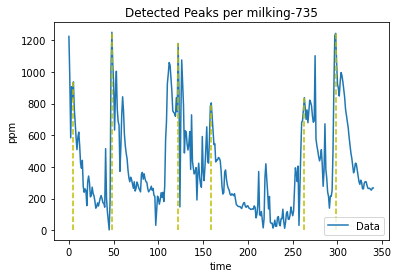

492
[ 19  62 207 246 313]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

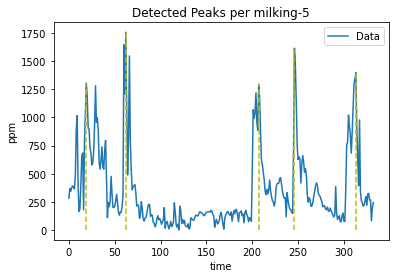

493
[ 32 103 279]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 

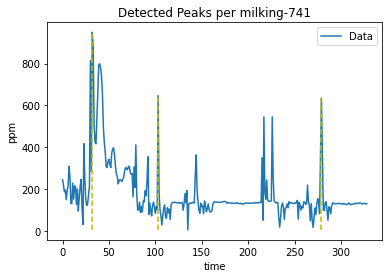

494
[]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 56, 123: 59, 12

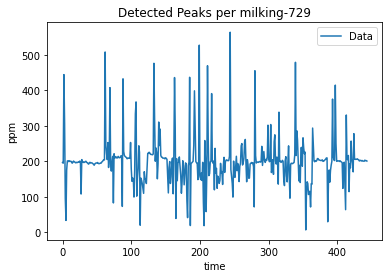

495
[  3  59 124 182 244 297 361 410]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24

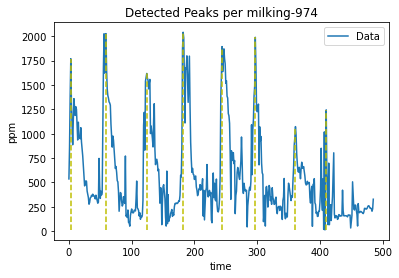

496
[ 31  83 131 183]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

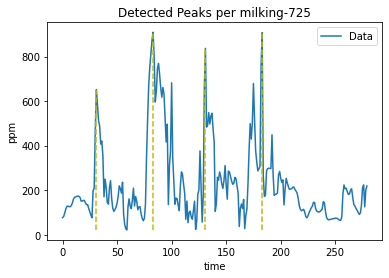

497
[  6  82 143 214 272]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

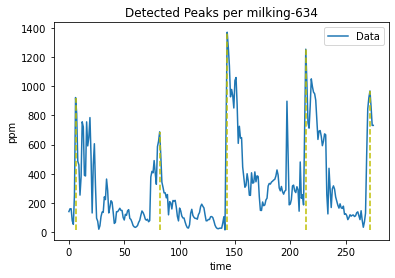

498
[133 182 230 275]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 122: 

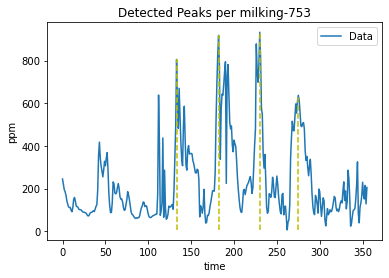

499
[ 21 136 209 279 332]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 24, 1

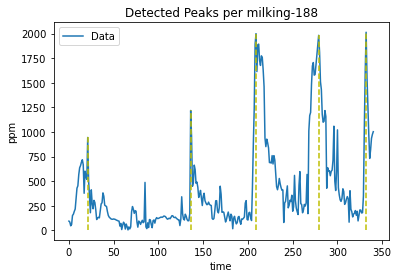

500
[ 29  87 127 186 230 267]
{1: 19, 2: 100, 3: 30, 4: 52, 5: 60, 6: 8, 7: 11, 8: 40, 9: 15, 10: 4, 11: 25, 12: 1, 13: 34, 14: 36, 15: 30, 16: 3, 17: 3, 18: 6, 19: 12, 20: 20, 21: 24, 22: 28, 23: 37, 24: 65, 25: 13, 26: 6, 27: 'NaN', 28: 'NaN', 29: 77, 30: 4, 31: 10, 32: 128, 33: 'NaN', 34: 'NaN', 35: 32, 36: 6, 37: 16, 38: 26, 39: 21, 40: 83, 41: 114, 42: 166, 43: 29, 44: 16, 45: 2, 46: 11, 47: 13, 48: 71, 49: 59, 50: 19, 51: 42, 52: 5, 53: 7, 54: 11, 55: 26, 56: 7, 57: 26, 58: 32, 59: 62, 60: 27, 61: 33, 62: 1, 63: 14, 64: 8, 65: 50, 66: 16, 67: 47, 68: 20, 69: 10, 70: 24, 71: 8, 72: 2, 73: 109, 74: 36, 75: 5, 76: 2, 77: 8, 78: 2, 79: 41, 80: 34, 81: 69, 82: 27, 83: 4, 84: 8, 85: 1, 86: 11, 87: 50, 88: 46, 89: 1, 90: 13, 91: 16, 92: 45, 93: 4, 94: 38, 95: 285, 96: 108, 97: 6, 98: 40, 99: 'NaN', 100: 51, 101: 2, 102: 16, 103: 141, 104: 58, 105: 38, 106: 31, 107: 30, 108: 7, 109: 5, 110: 63, 111: 29, 112: 44, 113: 12, 114: 10, 115: 23, 116: 37, 117: 5, 118: 7, 119: 16, 120: 24, 121: 2

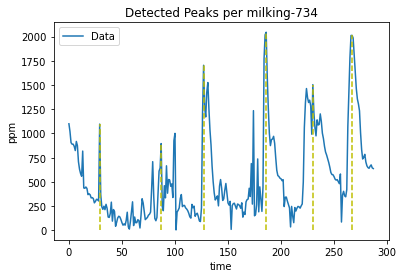

In [28]:
first_peaks = dict()
last_peaks = dict()
durations = list()

for mungitura in mungiture[0:500]:  
    
    print(mungitura)

    milking_ch4 = mandria[mandria['Milking_number'] == mungitura]
    milking_ch4 = milking_ch4.reset_index(drop=True)
        
    ch4=milking_ch4['CH4']
    
    milking_length = len(ch4)
    durations.append(milking_length)
    
    cow = milking_ch4.iloc[0,0]
    
    #da controllare ogni volta in base al file
    #date = milking_ch4.iloc[0,4] 
    
    #Wait 20 sec before the detection of the next peak
    time_interval=35
    
    #calcolo della media per mungitura (da usare in futuro?)
    #mean_height = milking_ch4['CH4'].mean()
    
    # Find peaks
    peaks, properties = find_peaks(ch4, height=mean_ch4, distance=time_interval)
    
    if len(peaks)>0:
        first_peaks[mungitura] = peaks[0]
        last_peaks[mungitura] = peaks[-1]
    else:
        first_peaks[mungitura] = "NaN"
        last_peaks[mungitura] = "NaN"
    
    print(peaks)
    print(first_peaks)
    print(last_peaks)
    
    # Count the number of peaks
    num_peaks = len(peaks)
    
    # Save the count to a new column in the DataFrame
    milking_ch4['num_peaks'] = num_peaks
    

    # Plot the data
    ch4.plot(x='CH4', label='Data')
    
    # Plot the detected peaks
    #ch4.plot(x='peaks', label='Detected Peaks')

    # Optionally, mark the heights of the peaks
    plt.vlines(x=peaks, ymin=min(ch4), ymax=ch4[peaks], colors="y", linestyles="dashed")

    # Add labels and title
    plt.title("Detected Peaks per milking" + "-" + str(cow))
    plt.xlabel("time")
    plt.ylabel("ppm")
    plt.legend()
    
    '''
    directory = "./estate/ch4_peaks/"
    if not os.path.exists(directory):
        os.makedirs(directory)
    file_path = directory + str(mungitura) + ".png"
    plt.savefig(file_path, format="png", dpi=250)
    '''
    plt.show()
    
    
    matrix.append(milking_ch4)   

In [29]:
print(first_peaks.keys() == last_peaks.keys())
print(len(durations) == len(first_peaks))

True
True


In [30]:
first_and_last_peaks_df = pd.DataFrame()
first_and_last_peaks_df['Milking_number'] = first_peaks.keys()
first_and_last_peaks_df['First_peaks_index'] = first_peaks.values()
first_and_last_peaks_df['Last_peaks_index'] = last_peaks.values()

first_and_last_peaks_df['Milking_durations_check'] = durations
first_and_last_peaks_df.head(10)

first_and_last_peaks_df.to_csv("./inverno/ch4_first_and_last_peaks.csv", index=None)

In [31]:
df = pd.read_csv("./inverno/ch4_first_and_last_peaks.csv")
df.head()

,Milking_number,First_peaks_index,Last_peaks_index,Milking_durations_check
0,1,19.0,126.0,137
1,2,100.0,267.0,304
2,3,30.0,161.0,230
3,4,52.0,171.0,208
4,5,60.0,314.0,342


In [32]:
mean_first_peaks = df['First_peaks_index'].mean()
print(mean_first_peaks)

28.919917864476385


In [33]:
mean_last_peaks = df['Last_peaks_index'].mean()
print(mean_last_peaks)

286.4332648870637


In [ ]:
# Concatenate all DataFrames in the list into a single DataFrame
combined_df = pd.concat(matrix, ignore_index=True)

mean_ch4_1= combined_df['CH4'].mean()

#filter_peaks=combined_df[combined_df['num_peaks']>= 2]

#mean_ch4_2= filter_peaks['CH4'].mean()


#filter_peaks.drop(columns=['Entry_time','Milking_duration','Exit_time'], inplace=True)

# Salva il DataFrame combinato in un nuovo file CSV.
output_file = 'C:/Users/chiar/Dropbox/Prove_MOOLOGGER/Troscia_frisone/Dati_giu_lug_2024/ch4_peaks_no_cut.csv'
combined_df.to_csv(output_file, index=False)